# Неделя 7. Абсолютно непрерывные случайные величины

#### Импорты и настройка

In [ ]:
from collections.abc import Callable
from functools import partial
from typing import Any, Optional

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, optimize
from scipy.signal import fftconvolve
from scipy.special import gammainc, gammaincinv, gammaln
from scipy.stats import (
    beta,
    cauchy,
    expon,
    gamma,
    norm,
    rv_continuous,
    uniform,
)

In [2]:
print(f"NumPy {np.__version__},  Matplotlib {plt.matplotlib.__version__}")

NumPy 2.5.1,  Matplotlib 3.11.0


In [3]:
RNG = np.random.default_rng(42)  # Фиксируем сид для генератора

In [ ]:
# Настройка для графиков
plt.rcParams.update(
    {
        "figure.constrained_layout.use": True,
        "figure.dpi": 120,
        "axes.grid": True,
        "grid.alpha": 0.35,
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "legend.fontsize": 9,
        "legend.framealpha": 0.85,
        "legend.edgecolor": "#cccccc",
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
    }
)

COLORS = {
    "theory": "#2c7bb6",  # синий — теоретическая плотность
    "empirical": "#fdae61",  # оранжевый — гистограмма выборки
    "cdf": "#1b9e77",  # зелёный — CDF
    "inverse": "#d7191c",  # красный — inverse transform
    "reference": "#d7199b",  # фиолетовый — опорные линии / огибающая
}


def _stylise_ax(ax: plt.Axes, title: str, xlabel: str, ylabel: str) -> None:
    """Единообразное оформление осей: заголовок, подписи, сетка под данными"""
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)


def plot_pdf(
    x: np.ndarray,
    pdf: np.ndarray,
    title: str = "Плотность распределения (PDF)",
    color: str = COLORS["theory"],
    ax: plt.Axes | None = None,
    alpha: float = 0.30,
    label: str | None = "Теоретическая PDF",
    fill: bool = True,
) -> plt.Axes:
    """Кривая плотности с опциональной заливкой под графиком"""
    if ax is None:
        _, ax = plt.subplots()

    x = np.asarray(x)
    pdf = np.asarray(pdf)
    ax.plot(x, pdf, color=color, linewidth=2.2, label=label)
    if fill:
        ax.fill_between(x, pdf, 0.0, color=color, alpha=alpha, linewidth=0)

    ax.axhline(0.0, color="#aaaaaa", linewidth=0.7, alpha=0.6)
    _stylise_ax(ax, title, "$x$", "$f(x)$")
    if label:
        ax.legend(loc="best")
    ax.set_ylim(bottom=0)
    return ax


def plot_cdf_continuous(
    x: np.ndarray,
    cdf: np.ndarray,
    title: str = "Функция распределения (CDF)",
    color: str = COLORS["cdf"],
    ax: Optional[plt.Axes] = None,
    label: Optional[str] = "Теоретическая CDF",
) -> plt.Axes:
    """Гладкая функция распределения непрерывной случайной величины"""
    if ax is None:
        _, ax = plt.subplots()

    ax.plot(x, cdf, color=color, linewidth=2.2, label=label)
    for y_line in (0.0, 1.0):
        ax.axhline(y=y_line, color="#aaaaaa", linestyle="-.", linewidth=0.7, alpha=0.5)
    _stylise_ax(ax, title, "$x$", "$F(x)$")
    ax.set_ylim(-0.05, 1.08)
    if label:
        ax.legend(loc="lower right")
    return ax

In [5]:
def plot_histogram_vs_pdf(
    samples: np.ndarray,
    pdf: Callable[[np.ndarray], np.ndarray],
    x_grid: np.ndarray,
    title: str = "Гистограмма выборки и плотность",
    bins: int = 60,
    hist_range: Optional[tuple] = None,
    color_hist: str = COLORS["empirical"],
    color_pdf: str = COLORS["theory"],
    ax: Optional[plt.Axes] = None,
    label_hist: Optional[str] = None,
    label_pdf: str = "Теоретическая PDF",
    weights: Optional[np.ndarray] = None,
) -> plt.Axes:
    """Нормированная гистограмма выборки поверх теоретической плотности"""
    if ax is None:
        _, ax = plt.subplots()

    n = len(samples)
    if label_hist is None:
        label_hist = f"Гистограмма ($n = {n:,}$)"
    ax.hist(
        samples,
        bins=bins,
        density=(weights is None),
        range=hist_range,
        weights=weights,
        color=color_hist,
        alpha=0.55,
        edgecolor="white",
        linewidth=0.5,
        label=label_hist,
    )
    x_grid = np.asarray(x_grid)
    ax.plot(x_grid, pdf(x_grid), color=color_pdf, linewidth=2.2, label=label_pdf)
    _stylise_ax(ax, title, "$x$", "Плотность")
    ax.legend(loc="best")
    ax.set_ylim(bottom=0)
    return ax


def plot_two_pdfs(
    x1: np.ndarray,
    f1: np.ndarray,
    x2: np.ndarray,
    f2: np.ndarray,
    title: str = "Сравнение двух плотностей",
    label1: str = "PDF 1",
    label2: str = "PDF 2",
    color1: str = COLORS["theory"],
    color2: str = COLORS["inverse"],
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:
    """Сравнение двух плотностей на одном графике"""
    if ax is None:
        _, ax = plt.subplots()

    ax.plot(x1, f1, color=color1, linewidth=2.2, label=label1)
    ax.plot(x2, f2, color=color2, linewidth=2.2, linestyle="--", label=label2)
    ax.axhline(0.0, color="#aaaaaa", linewidth=0.7, alpha=0.6)
    _stylise_ax(ax, title, "$x$", "$f(x)$")
    ax.legend(loc="best")
    ax.set_ylim(bottom=0)
    return ax


def plot_inverse_transform_demo(
    cdf: Callable[[np.ndarray], np.ndarray],
    ppf: Callable[[float], float],
    x_grid: np.ndarray,
    u_demo: float = 0.65,
    title: str = "Метод обратного преобразования",
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:
    """Визуализация обратного преобразования: u -> F^{-1}(u)"""
    if ax is None:
        _, ax = plt.subplots()

    x_grid = np.asarray(x_grid)
    plot_cdf_continuous(x_grid, cdf(x_grid), ax=ax, label="CDF $F(x)$")

    x_inv = float(ppf(u_demo))
    ax.axhline(
        y=u_demo,
        color=COLORS["inverse"],
        linestyle="--",
        linewidth=1.5,
        alpha=0.7,
        label=f"$u = {u_demo}$",
    )
    ax.vlines(
        x=x_inv,
        ymin=0,
        ymax=u_demo,
        colors=COLORS["inverse"],
        linestyles=":",
        linewidth=1.5,
        alpha=0.7,
    )
    ax.scatter(
        [x_inv],
        [u_demo],
        color=COLORS["inverse"],
        s=50,
        zorder=10,
        edgecolors="white",
        linewidth=1.2,
    )

    span = float(x_grid[-1] - x_grid[0])
    ax.annotate(
        f"$F^{{-1}}({u_demo}) = {x_inv:.3f}$",
        xy=(x_inv, u_demo),
        xytext=(x_inv + 0.15 * span, u_demo - 0.12),
        arrowprops=dict(arrowstyle="->", color=COLORS["inverse"], lw=1.3),
        fontsize=11,
        color=COLORS["inverse"],
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor=COLORS["inverse"],
            alpha=0.85,
        ),
    )
    _stylise_ax(ax, title, "$x$", "$F(x)$")
    ax.set_ylim(-0.05, 1.16)
    ax.legend(loc="lower right")
    return ax


def plot_distribution_dashboard(
    pdf: Callable[[np.ndarray], np.ndarray],
    cdf: Callable[[np.ndarray], np.ndarray],
    ppf: Callable[[float], float],
    x_grid: np.ndarray,
    samples: Optional[np.ndarray] = None,
    suptitle: str = "Непрерывное распределение",
    u_demo: float = 0.65,
    hist_range: Optional[tuple] = None,
) -> plt.Figure:
    """Панель: PDF (+ гистограмма), inverse transform, CDF (+ ECDF)"""
    n_cols = 3 if samples is not None else 2
    fig, axes = plt.subplots(1, n_cols, figsize=(6.2 * n_cols, 5.0))
    # Когда n_cols = 2, axes — массив из 2 осей; оборачиваем в list
    if n_cols == 2:
        axes = list(axes)

    x_grid = np.asarray(x_grid)
    # Диапазон гистограммы берём по выборке, а не по отступам сетки x_grid,
    # чтобы крайние корзины не оставались полупустыми (напр. U[0,1] на
    # сетке [-0.2, 1.2]).
    if hist_range is None and samples is not None:
        hist_range = (float(np.min(samples)), float(np.max(samples)))

    if samples is not None:
        plot_histogram_vs_pdf(
            samples,
            pdf,
            x_grid,
            title="PDF и гистограмма",
            hist_range=hist_range,
            ax=axes[0],
        )
    else:
        plot_pdf(x_grid, pdf(x_grid), title="PDF", ax=axes[0])

    plot_inverse_transform_demo(cdf, ppf, x_grid, u_demo=u_demo, ax=axes[1])

    if samples is not None and n_cols >= 3:
        plot_cdf_continuous(
            x_grid, cdf(x_grid), title="Теоретическая и эмпирическая CDF", ax=axes[2]
        )
        # Эмпирическая функция распределения (ECDF) той же выборки.
        axes[2].ecdf(
            samples,
            color=COLORS["empirical"],
            linestyle="--",
            linewidth=1.8,
            label="Эмпирическая CDF (ECDF)",
        )
        axes[2].legend(loc="lower right")

    fig.suptitle(suptitle, fontsize=16, fontweight="bold")
    return fig


def plot_acceptance_rejection(
    target_pdf: Callable[[np.ndarray], np.ndarray],
    proposal_pdf: Callable[[np.ndarray], np.ndarray],
    M: float,
    x_grid: np.ndarray,
    samples: Optional[np.ndarray] = None,
    title: str = "Метод принятия-отклонения",
    ax: Optional[plt.Axes] = None,
) -> plt.Axes:
    """Целевая плотность, огибающая M*g и гистограмма принятой выборки"""
    if ax is None:
        _, ax = plt.subplots()

    x_grid = np.asarray(x_grid)
    ax.plot(
        x_grid,
        target_pdf(x_grid),
        color=COLORS["theory"],
        linewidth=2.4,
        label="Целевая плотность $f$",
    )
    ax.plot(
        x_grid,
        M * proposal_pdf(x_grid),
        color=COLORS["reference"],
        linewidth=2.0,
        linestyle="--",
        label=rf"$M \cdot g$ ($M = {M:.3f}$)",
    )
    ax.fill_between(
        x_grid,
        target_pdf(x_grid),
        M * proposal_pdf(x_grid),
        color=COLORS["reference"],
        alpha=0.12,
    )
    ax.fill_between(x_grid, target_pdf(x_grid), 0.0, color=COLORS["theory"], alpha=0.15)
    if samples is not None:
        ax.hist(
            samples,
            bins=60,
            density=True,
            color=COLORS["empirical"],
            alpha=0.5,
            edgecolor="white",
            linewidth=0.4,
            label=f"Принятая выборка ($n = {len(samples):,}$)",
        )
    ax.axhline(0.0, color="#aaaaaa", linewidth=0.7, alpha=0.6)
    _stylise_ax(ax, title, "$x$", "Плотность")
    ax.legend(loc="best")
    ax.set_ylim(bottom=0)
    return ax

## Понятие абсолютно непрерывной случайной величины

Случайная величина $X$ называется **абсолютно непрерывной**, если существует
неотрицательная функция $f_X(x)$ — **плотность** (PDF, Probability Density
Function), такая, что функция распределения представима в виде интеграла:

$$F_X(x) = \mathbb{P}(X \le x) = \int_{-\infty}^{x} f_X(t)\,dt$$

Свойства плотности:

- $f_X(x) \ge 0$ почти всюду
- нормировка: $\displaystyle\int_{-\infty}^{\infty} f_X(x)\,dx = 1$
- в точках непрерывности $f_X$ выполнено $F'_X(x) = f_X(x)$
- вероятность попадания в множество $A$:
  $\displaystyle\mathbb{P}(X \in A) = \int_A f_X(x)\,dx$

### Числовые характеристики непрерывной СВ:

**Математическое ожидание:**
  $\displaystyle\mathbb{E}[X] = \int_{-\infty}^{\infty} x\,f_X(x)\,dx$

**Дисперсия:**
  $\displaystyle\mathbb{D}[X] = \mathbb{E}\!\left[(X-\mathbb{E}[X])^2\right]
  = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$

**Мода** $\operatorname{Mode}(X)$ — точка (точки) локального максимума
   плотности. Если локальных  максимумов несколько, распределение называют *мультимодальным*   (бимодальным, тримодальным и т.д.)

**Квантиль порядка** $q \in (0, 1)$ — значение $x_q = F^{-1}(q)$:
  $\displaystyle x_q = \inf\,\{\,x \mid F_X(x) \ge q\,\}$;
  для $q = 0.5$ получаем **медиану**, для $q = 0.25$ и $q = 0.75$ — квартили

**Носитель (support)**
Пусть $\mu$ — вероятностная мера (распределение) на $(\mathbb{R}, \mathcal{B}(\mathbb{R}))$. Носителем распределения $\mu$ называется множество 

$
\operatorname{supp}\mu :=
\bigcap\left\{
F \subseteq \mathbb{R}
\mid
F \text{ замкнуто},\ \mu(F)=1
\right\},
$

т. е. пересечение всех замкнутых множеств полной меры.

In [6]:
def mean_continuous(
    pdf: Callable[[float], float],
    a: float,
    b: float,
) -> float:
    """Математическое ожидание через численное интегрирование"""
    return float(integrate.quad(lambda x: float(x * pdf(x)), a, b)[0])


def variance_continuous(
    pdf: Callable[[float], float],
    a: float,
    b: float,
) -> float:
    """Дисперсия: E[X^2] - (E[X])^2"""
    mu = mean_continuous(pdf, a, b)
    ex2 = float(integrate.quad(lambda x: float(x**2 * pdf(x)), a, b)[0])
    return ex2 - mu**2


def quantile_continuous(
    cdf: Callable[[float], float],
    q: float,
    a: float,
    b: float,
) -> float:
    """Квантиль как корень уравнения F(x) = q"""
    if not (0.0 < q < 1.0):
        raise ValueError(f"q должно быть в (0, 1), получено {q}")

    return float(optimize.brentq(lambda x: float(cdf(x)) - q, a, b))


def median_continuous(
    cdf: Callable[[float], float],
    a: float,
    b: float,
) -> float:
    """Медиана — квантиль порядка 0.5"""
    return quantile_continuous(cdf, 0.5, a, b)

In [7]:
def describe_continuous_distribution(
    name: str,
    param_str: str,
    pdf: Callable[[np.ndarray], np.ndarray],
    cdf: Callable[[float], float],
    a: float,
    b: float,
    samples: np.ndarray,
    scipy_dist: Optional[Any] = None,
    theoretical_mean: Optional[float] = None,
    theoretical_var: Optional[float] = None,
    n_grid: int = 2000,
) -> None:
    """Сводка по непрерывному распределению и сверка со scipy"""
    grid = np.linspace(a, b, n_grid)

    norm = float(integrate.quad(lambda x: float(pdf(x)), a, b)[0])
    mean_val = mean_continuous(pdf, a, b)
    var_val = variance_continuous(pdf, a, b)
    med_val = median_continuous(cdf, a, b)

    mean_str = f"{mean_val:.4f}"
    if theoretical_mean is not None:
        mean_str += f"  (теор. {theoretical_mean:.4f})"
    var_str = f"{var_val:.4f}"
    if theoretical_var is not None:
        var_str += f"  (теор. {theoretical_var:.4f})"

    match_str = "-"
    if scipy_dist is not None:
        match = np.allclose(pdf(grid), scipy_dist.pdf(grid), atol=1e-10)
        match_str = "ok" if match else "РАСХОЖДЕНИЕ!"

    w = 32
    print(f"━━━ {name} ({param_str}) ━━━")
    print(f"  {'Нормировка (интеграл от PDF):':<{w}} {norm:.6f}")
    if scipy_dist is not None:
        print(f"  {'PDF совпадает с scipy:':<{w}} {match_str}")
    print(f"  {'Рассчитанное мат. ожидание:':<{w}} {mean_str}")
    print(f"  {'Рассчитанная дисперсия:':<{w}} {var_str}")
    print(f"  {'Рассчитанная медиана:':<{w}} {med_val:.4f}")
    print()
    print("━━━ Результат генерации выборки ━━━")
    print(f"  {'Сгенерировано значений:':<{w}} {len(samples):.0f}")
    print(f"  {'Выборочное среднее:':<{w}} {samples.mean():.4f}")
    print(f"  {'Выборочная дисперсия:':<{w}} {samples.var(ddof=1):.4f}")
    print(f"  {'Выборочная медиана:':<{w}} {np.median(samples):.4f}")
    print(f"  {'Мин./макс. выборки:':<{w}} {samples.min():.4f} / {samples.max():.4f}")
    print()

## Моделирование непрерывных случайных величин

Постановка задачи та же, что и в дискретном случае: есть генератор
псевдослучайных чисел, значения которого принимаются за выборку из
стандартного равномерного распределения $U[0,1]$

**Часть 1. Метод обратной функции распределения (inverse transform sampling)**

Если известна квантильная функция $F^{-1}(q)$, то случайная величина

$$Y = F^{-1}(U),\qquad U \sim U[0,1] $$

имеет функцию распределения $F$:

$$\mathbb{P}\!\left(F^{-1}(U) \le x\right)
= \mathbb{P}(U \le F(x)) = F(x)$$


In [8]:
def inverse_transform_continuous(
    ppf: Callable[[np.ndarray], np.ndarray],
    n_samples: int,
    rng: np.random.Generator = RNG,
) -> np.ndarray:
    """Генерация выборки методом обратной функции распределения"""
    u = rng.uniform(size=n_samples)
    return ppf(u)


def make_ppf_from_cdf_continuous(
    cdf: Callable[[np.ndarray], np.ndarray],
    grid: np.ndarray,
) -> Callable[[np.ndarray], np.ndarray]:
    """Квантильная функция по табулированной CDF (кусочно-линейная
    интерполяция обратной функции)"""
    grid = np.asarray(grid, dtype=float)
    cdf_values = np.asarray(cdf(grid), dtype=float)
    lo = float(cdf_values[0])
    hi = float(cdf_values[-1])

    def ppf(u: np.ndarray) -> np.ndarray:
        u = np.asarray(u, dtype=float)
        return np.interp(np.clip(u, lo, hi), cdf_values, grid)

    return ppf

**2.1.** Равномерное распределение $U[a, b]$

| Характеристика | Формула |
|---|---|
| Носитель | $[a, b]$ |
| PDF | $\displaystyle f(x) = \frac{1}{b-a}$ для $x \in [a,b]$ |
| CDF | $\displaystyle F(x) = \frac{x-a}{b-a}$ для $x \in [a,b]$ |
| $\mathbb{E}[X]$ | $\displaystyle \frac{a+b}{2}$ |
| $\mathbb{D}[X]$ | $\displaystyle \frac{(b-a)^2}{12}$ |
| $F^{-1}(u)$ | $a + (b-a)\,u$ |

In [9]:
def pdf_uniform(x: np.ndarray, a: float = 0.0, b: float = 1.0) -> np.ndarray:
    x = np.asarray(x)
    return np.where((x >= a) & (x <= b), 1.0 / (b - a), 0.0)


def cdf_uniform(x: np.ndarray, a: float = 0.0, b: float = 1.0) -> np.ndarray:
    x = np.asarray(x)
    return np.clip((x - a) / (b - a), 0.0, 1.0)


def ppf_uniform(u: np.ndarray, a: float = 0.0, b: float = 1.0) -> np.ndarray:
    return a + (b - a) * np.asarray(u)

In [10]:
# Расчёт параметров и генерация выборки — U[a, b]
A_UNIF = 0.0
B_UNIF = 1.0
N_SAMPLES = 1_000_000

pdf_u = partial(pdf_uniform, a=A_UNIF, b=B_UNIF)
cdf_u = partial(cdf_uniform, a=A_UNIF, b=B_UNIF)
ppf_u = partial(ppf_uniform, a=A_UNIF, b=B_UNIF)

samples_unif = inverse_transform_continuous(ppf_u, N_SAMPLES, RNG)
x_grid_unif = np.linspace(A_UNIF - 0.2, B_UNIF + 0.2, 500)

describe_continuous_distribution(
    "Равномерное распределение",
    f"[{A_UNIF:g}, {B_UNIF:g}]",
    pdf_u,
    cdf_u,
    A_UNIF,
    B_UNIF,
    samples_unif,
    uniform(loc=A_UNIF, scale=B_UNIF - A_UNIF),
    theoretical_mean=(A_UNIF + B_UNIF) / 2.0,
    theoretical_var=(B_UNIF - A_UNIF) ** 2 / 12.0,
)

━━━ Равномерное распределение ([0, 1]) ━━━
  Нормировка (интеграл от PDF):    1.000000
  PDF совпадает с scipy:           ok
  Рассчитанное мат. ожидание:      0.5000  (теор. 0.5000)
  Рассчитанная дисперсия:          0.0833  (теор. 0.0833)
  Рассчитанная медиана:            0.5000

━━━ Результат генерации выборки ━━━
  Сгенерировано значений:          1000000
  Выборочное среднее:              0.5000
  Выборочная дисперсия:            0.0833
  Выборочная медиана:              0.4998
  Мин./макс. выборки:              0.0000 / 1.0000



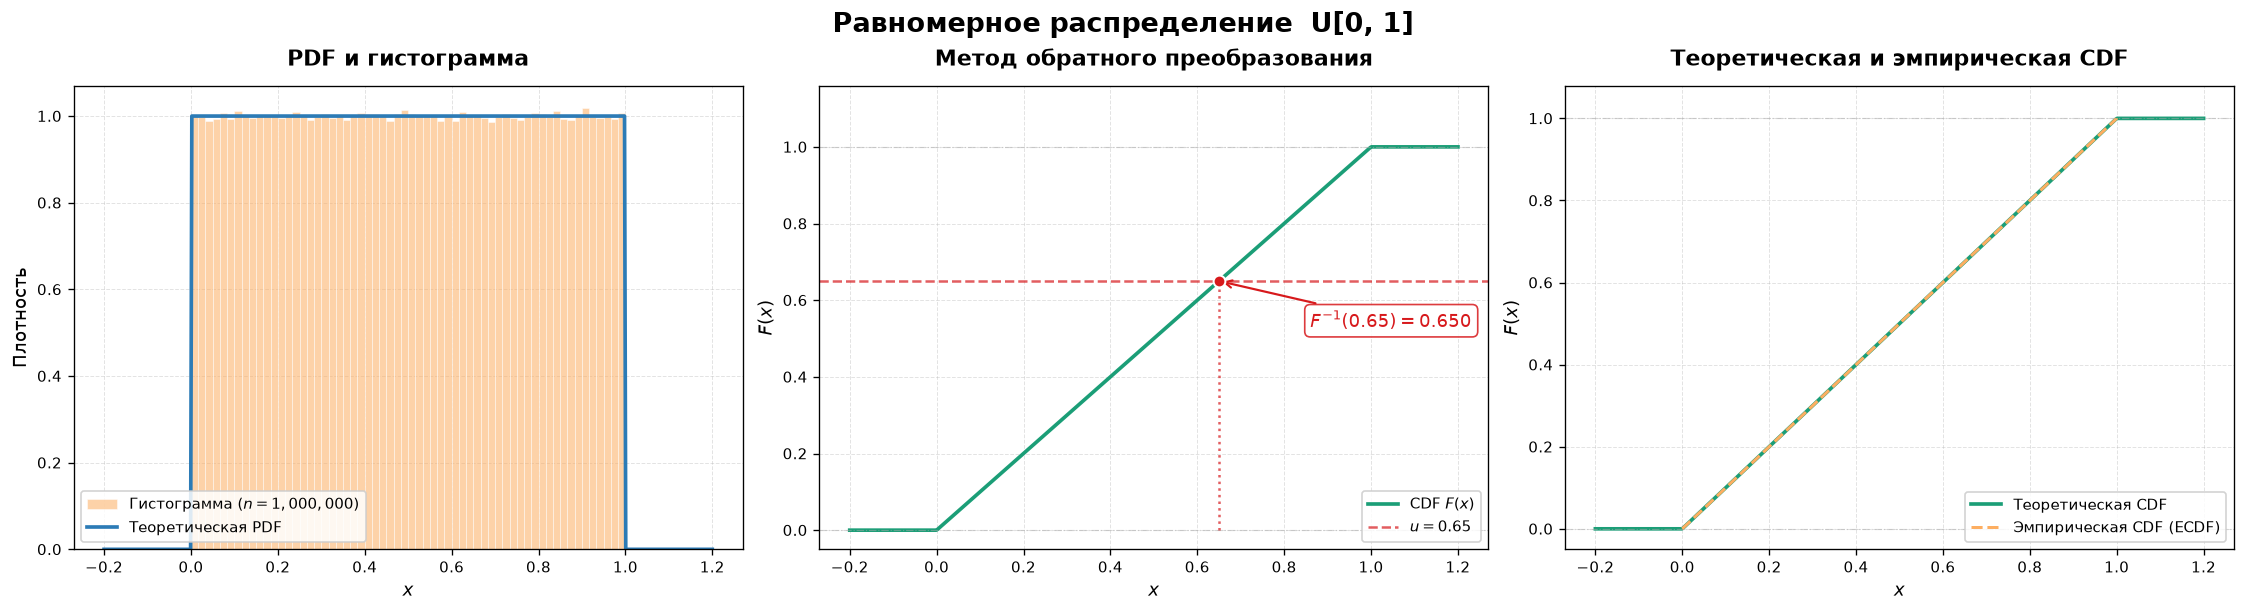

In [12]:
# Визуализация
fig_unif = plot_distribution_dashboard(
    pdf_u,
    cdf_u,
    ppf_u,
    x_grid_unif,
    samples=samples_unif,
    suptitle=f"Равномерное распределение  U[{A_UNIF:g}, {B_UNIF:g}]",
    u_demo=0.65,
)
plt.show()

**2.2.** Экспоненциальное распределение $\operatorname{Exp}(\lambda)$


| Характеристика | Формула |
|---|---|
| Носитель | $x \ge 0$ |
| PDF | $\displaystyle f(x) = \lambda e^{-\lambda x}$ |
| CDF | $\displaystyle F(x) = 1 - e^{-\lambda x}$ |
| $\mathbb{E}[X]$ | $\displaystyle \frac{1}{\lambda}$ |
| $\mathbb{D}[X]$ | $\displaystyle \frac{1}{\lambda^2}$ |
| $F^{-1}(u)$ | $\displaystyle -\frac{\ln(1-u)}{\lambda}$ |

In [13]:
def pdf_exp(x: np.ndarray, lam: float) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    return np.where(x >= 0, lam * np.exp(-lam * x), 0.0)


def cdf_exp(x: np.ndarray, lam: float) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    return np.where(x >= 0, -np.expm1(-lam * x), 0.0)


def ppf_exp(u: np.ndarray, lam: float) -> np.ndarray:
    return -np.log1p(-np.asarray(u)) / lam

In [14]:
# Расчёт параметров и генерация выборки Exp(λ)
LAMBDA_EXP = 2.0
B_EXP = 8.0
N_SAMPLES = 1_000_000

pdf_e = partial(pdf_exp, lam=LAMBDA_EXP)
cdf_e = partial(cdf_exp, lam=LAMBDA_EXP)
ppf_e = partial(ppf_exp, lam=LAMBDA_EXP)

samples_exp = inverse_transform_continuous(ppf_e, N_SAMPLES, RNG)
x_grid_exp = np.linspace(0.0, B_EXP, 500)

describe_continuous_distribution(
    "Экспоненциальное распределение",
    f"λ = {LAMBDA_EXP}",
    pdf_e,
    cdf_e,
    0.0,
    B_EXP,
    samples_exp,
    expon(scale=1.0 / LAMBDA_EXP),
    theoretical_mean=1.0 / LAMBDA_EXP,
    theoretical_var=1.0 / LAMBDA_EXP**2,
)

━━━ Экспоненциальное распределение (λ = 2.0) ━━━
  Нормировка (интеграл от PDF):    1.000000
  PDF совпадает с scipy:           ok
  Рассчитанное мат. ожидание:      0.5000  (теор. 0.5000)
  Рассчитанная дисперсия:          0.2500  (теор. 0.2500)
  Рассчитанная медиана:            0.3466

━━━ Результат генерации выборки ━━━
  Сгенерировано значений:          1000000
  Выборочное среднее:              0.4997
  Выборочная дисперсия:            0.2501
  Выборочная медиана:              0.3462
  Мин./макс. выборки:              0.0000 / 7.5659



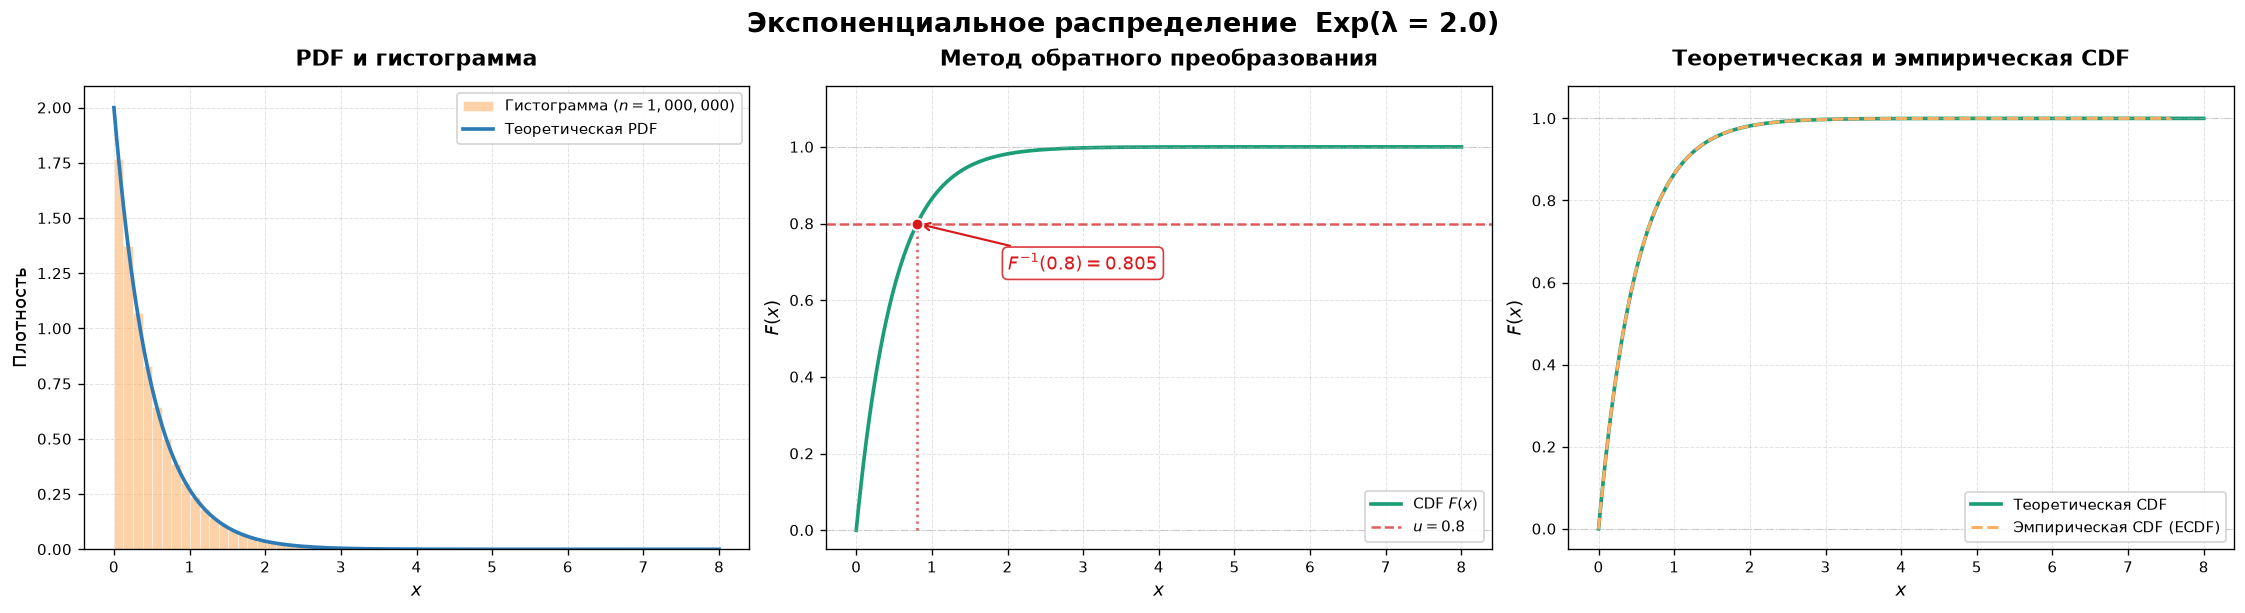

In [15]:
# Визуализация
fig_exp = plot_distribution_dashboard(
    pdf_e,
    cdf_e,
    ppf_e,
    x_grid_exp,
    samples=samples_exp,
    suptitle=f"Экспоненциальное распределение  Exp(λ = {LAMBDA_EXP})",
    u_demo=0.80,
)
plt.show()

**2.3.** Гамма-распределение $\operatorname{Gamma}(\alpha, \theta)$

Здесь $\alpha > 0$ — параметр формы, $\theta > 0$ — параметр масштаба.

| Характеристика | Формула |
|---|---|
| Носитель | $x > 0$ |
| PDF | $\displaystyle f(x) = \frac{x^{\alpha-1} e^{-x/\theta}}{\Gamma(\alpha)\,\theta^{\alpha}}$ |
| CDF | $\displaystyle F(x) = \frac{\gamma(\alpha, x/\theta)}{\Gamma(\alpha)}$  |
| $\mathbb{E}[X]$ | $\alpha\theta$ |
| $\mathbb{D}[X]$ | $\alpha\theta^2$ |
| $F^{-1}(u)$ | *нет замкнутой формулы* |

In [16]:
def pdf_gamma(x: np.ndarray, alpha: float, theta: float) -> np.ndarray:
    """Плотность гамма-распределения (численно устойчиво через gammaln)

    Параметры alpha/theta могут быть как скалярами, так и массивами той же
    формы, что и x (scipy передаёт их именно так внутрь rv_continuous)
    """
    x = np.asarray(x, dtype=float)
    alpha = np.asarray(alpha, dtype=float)
    theta = np.asarray(theta, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        log_pdf = (
            (alpha - 1.0) * np.log(np.maximum(x, 1e-300))
            - x / theta
            - alpha * np.log(theta)
            - gammaln(alpha)
        )
    out = np.exp(log_pdf)

    result = np.where(x > 0, out, 0.0)
    at_zero = x == 0.0
    result = np.where(at_zero & (alpha == 1.0), 1.0 / theta, result)
    result = np.where(at_zero & (alpha < 1.0), np.inf, result)
    return result


def cdf_gamma(x: np.ndarray, alpha: float, theta: float) -> np.ndarray:
    """Функция распределения через регуляризованную неполную гамма-функцию"""
    x = np.asarray(x, dtype=float)
    alpha = np.asarray(alpha, dtype=float)
    theta = np.asarray(theta, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        out = gammainc(alpha, x / theta)
    return np.where(x > 0, out, 0.0)

In [17]:
# Расчёт параметров и генерация выборки
ALPHA_G = 3.0
THETA_G = 2.0
B_G = 40.0
N_SAMPLES = 1_000_000

pdf_g = partial(pdf_gamma, alpha=ALPHA_G, theta=THETA_G)
cdf_g = partial(cdf_gamma, alpha=ALPHA_G, theta=THETA_G)

# Аналитической F^{-1} нет — строим её интерполяцией по табулированной CDF
grid_ppf_g = np.linspace(0.0, B_G, 2000)
ppf_g = make_ppf_from_cdf_continuous(cdf_g, grid_ppf_g)

samples_gamma = inverse_transform_continuous(ppf_g, N_SAMPLES, RNG)
x_grid_g = np.linspace(0.0, B_G, 500)

describe_continuous_distribution(
    "Гамма-распределение",
    f"α = {ALPHA_G}, θ = {THETA_G}",
    pdf_g,
    cdf_g,
    0.0,
    B_G,
    samples_gamma,
    gamma(a=ALPHA_G, scale=THETA_G),
    theoretical_mean=ALPHA_G * THETA_G,
    theoretical_var=ALPHA_G * THETA_G**2,
)

━━━ Гамма-распределение (α = 3.0, θ = 2.0) ━━━
  Нормировка (интеграл от PDF):    1.000000
  PDF совпадает с scipy:           ok
  Рассчитанное мат. ожидание:      6.0000  (теор. 6.0000)
  Рассчитанная дисперсия:          11.9994  (теор. 12.0000)
  Рассчитанная медиана:            5.3481

━━━ Результат генерации выборки ━━━
  Сгенерировано значений:          1000000
  Выборочное среднее:              5.9986
  Выборочная дисперсия:            12.0037
  Выборочная медиана:              5.3441
  Мин./макс. выборки:              0.0555 / 40.0000



In [18]:
# Сверка интерполированной квантильной функции со scipy
qs = np.array([0.05, 0.25, 0.50, 0.75, 0.95])
print("Сравнение квантилей (интерполяция vs scipy):")
for q in qs:
    print(
        f"  q = {q:.2f}  ->  интерп. {ppf_g(q):.4f}"
        f"   scipy {gamma.ppf(q, ALPHA_G, scale=THETA_G):.4f}"
    )

Сравнение квантилей (интерполяция vs scipy):
  q = 0.05  ->  интерп. 1.6354   scipy 1.6354
  q = 0.25  ->  интерп. 3.4546   scipy 3.4546
  q = 0.50  ->  интерп. 5.3481   scipy 5.3481
  q = 0.75  ->  интерп. 7.8408   scipy 7.8408
  q = 0.95  ->  интерп. 12.5916   scipy 12.5916


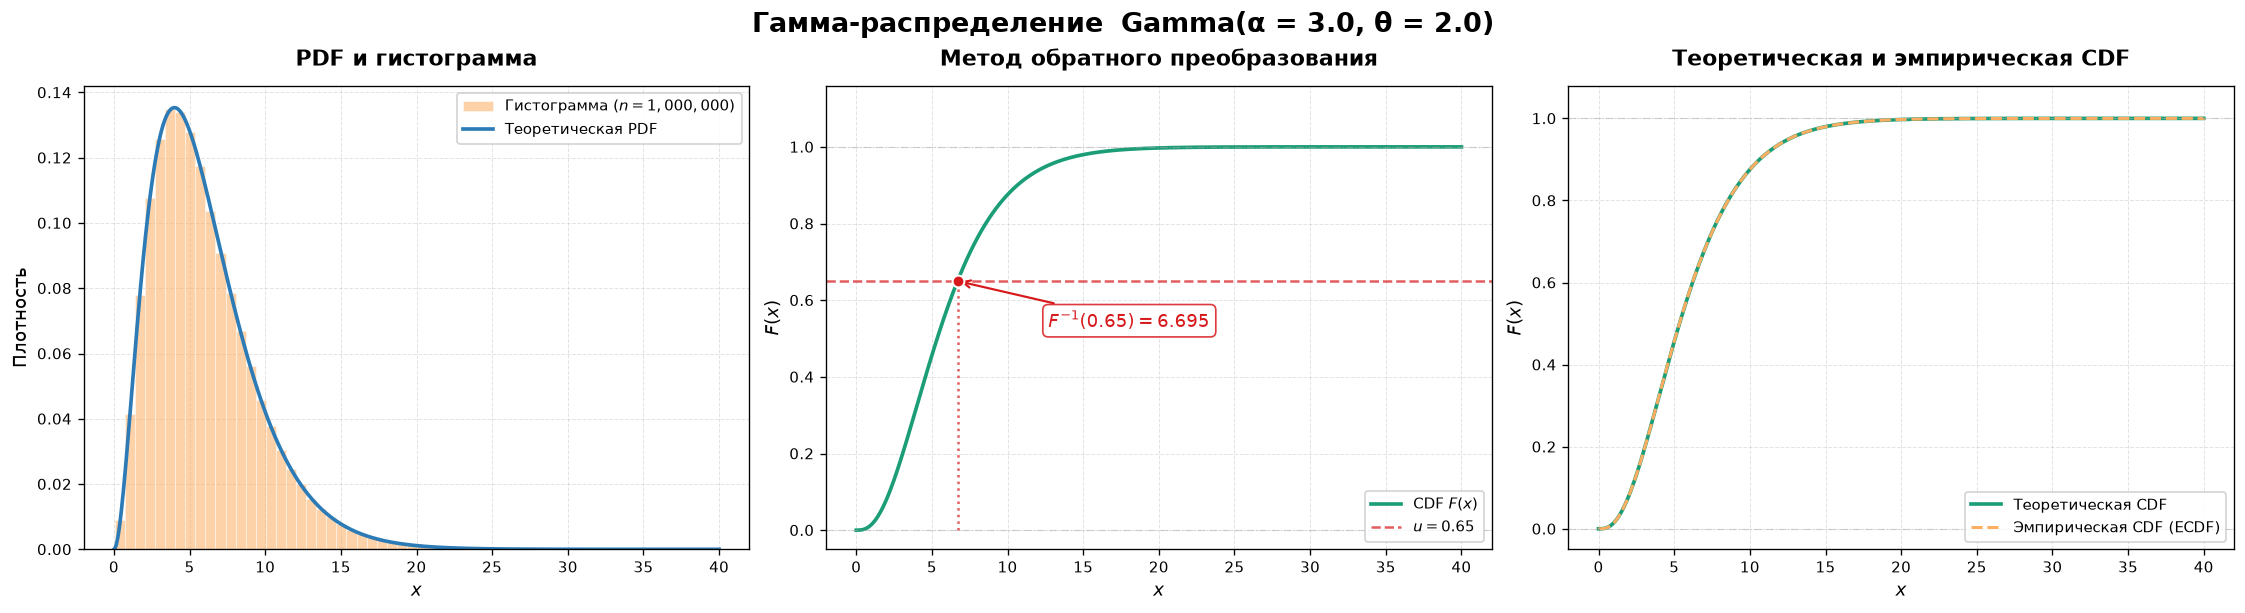

In [19]:
# Визуализация — Gamma(α, θ)
fig_gamma = plot_distribution_dashboard(
    pdf_g,
    cdf_g,
    ppf_g,
    x_grid_g,
    samples=samples_gamma,
    suptitle=f"Гамма-распределение  Gamma(α = {ALPHA_G}, θ = {THETA_G})",
    u_demo=0.65,
)
plt.show()

**Часть 2. Метод выборки с отклонением (acceptance-rejection method).**

Пусть нужно сгенерировать выборку из целевой плотности $f$, а мы уже умеем
генерировать выборку из вспомогательного распределения с известной плотностью $g$ (proposal density). Если удалось найти константу $M$ такую, что

$$f(x) \le M\,g(x)\quad\text{для всех } x,$$

то для генерации выборки используем следующий алгоритм:

1. Генерируем $X \sim g$ и $U \sim U[0,1]$ независимо
2. Если $\displaystyle U \le \frac{f(X)}{M\,g(X)}$ — принимаем $X$,
   иначе отклоняем и повторяем

Вероятность принять наблюдение равна $1/M$, поэтому на один принятый элемент в
среднем нужно $M$ попыток: чем ближе $M$ к единице, тем эффективнее метод.
Ключевой шаг — подобрать $g$, близкую по форме к $f$, и взять минимально
возможное $M$

In [20]:
def acceptance_rejection(
    target_pdf: Callable[[np.ndarray], np.ndarray],
    proposal_pdf: Callable[[np.ndarray], np.ndarray],
    proposal_rvs: Callable[[int, np.random.Generator], np.ndarray],
    M: float,
    n_samples: int,
    rng: np.random.Generator = RNG,
) -> np.ndarray:
    """Выборка из target_pdf методом выборки с отклонением"""
    accepted = []
    total = 0
    while total < n_samples:
        remaining = n_samples - total
        n_try = int(np.ceil(remaining * M * 1.25))
        x = np.asarray(proposal_rvs(n_try, random_state=rng))
        u = rng.uniform(size=n_try)
        accept_mask = u <= target_pdf(x) / (M * proposal_pdf(x))
        if accept_mask.any():
            batch = x[accept_mask]
            accepted.append(batch)
            total += batch.size
    return np.concatenate(accepted)[:n_samples]

**Пример A.** Бета-распределение $\operatorname{Beta}(2, 4)$ на $[0,1]$
с вспомогательным распределением $U[0,1]$. Плотность $f(x) = 20\,x\,(1-x)^3$, максимум в
$x = 1/4$, поэтому $M = f(1/4) = 135/64 \approx 2.1094$.

M = 2.1094,  теоретическая доля принятия 1/M = 0.4741
Выборочное среднее = 0.3336  (теор. 0.3333)


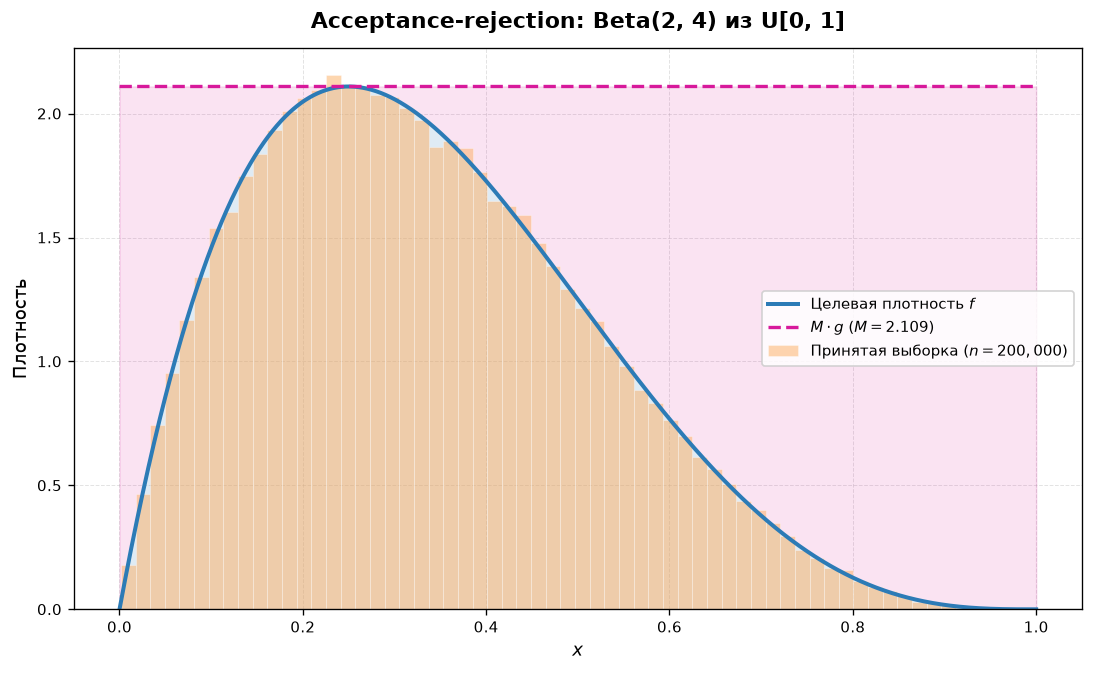

In [21]:
# Acceptance-rejection: Beta(2, 4) из U[0, 1]
ALPHA_B = 2.0
BETA_B = 4.0
N_AR = 200_000

target_beta = partial(beta.pdf, a=ALPHA_B, b=BETA_B)
proposal_unif_pdf = partial(pdf_uniform, a=0.0, b=1.0)
proposal_unif_rvs = lambda n, random_state: random_state.uniform(size=n)

grid_ar = np.linspace(0.0, 1.0, 5000)
M_beta = 135.0 / 64.0  # аналитическая константа f(1/4) для Beta(2, 4)
assert np.isclose(
    M_beta,
    float(np.max(target_beta(grid_ar) / proposal_unif_pdf(grid_ar))),
    atol=1e-4,
)

samples_beta_ar = acceptance_rejection(
    target_beta, proposal_unif_pdf, proposal_unif_rvs, M_beta, N_AR, RNG
)

print(f"M = {M_beta:.4f},  теоретическая доля принятия 1/M = {1.0 / M_beta:.4f}")
print(
    f"Выборочное среднее = {samples_beta_ar.mean():.4f}"
    f"  (теор. {ALPHA_B / (ALPHA_B + BETA_B):.4f})"
)

fig_ar_beta, ax_ar_beta = plt.subplots(figsize=(9, 5.5))
plot_acceptance_rejection(
    target_beta,
    proposal_unif_pdf,
    M_beta,
    grid_ar,
    samples=samples_beta_ar,
    ax=ax_ar_beta,
    title="Acceptance-rejection: Beta(2, 4) из U[0, 1]",
)
plt.show()

**Пример B.** Стандартное нормальное $\mathcal{N}(0,1)$ с предложением
Коши $\operatorname{Cauchy}(0,1)$. Отношение плотностей:

$$\frac{f(x)}{g(x)}
= \sqrt{\frac{\pi}{2}}\,(1 + x^2)\,e^{-x^2/2},$$

достигает максимума при $x = \pm 1$, откуда

$$M = \sqrt{\frac{\pi}{2}}\cdot 2\cdot e^{-1/2}
= \sqrt{\frac{2\pi}{e}} \approx 1.5203.$$

Вспомогательная плотность $g(x)$ обязана иметь не более легкие хвосты,
чем $f(x)$: иначе отношение $f(x)/g(x)$ при $|x| \to \infty$ будет
неограниченным и конечная константа $M$ не будет существовать.

M = 1.5203,  доля принятия 1/M = 0.6577
Выборочное среднее = 0.0034  (теор. 0)


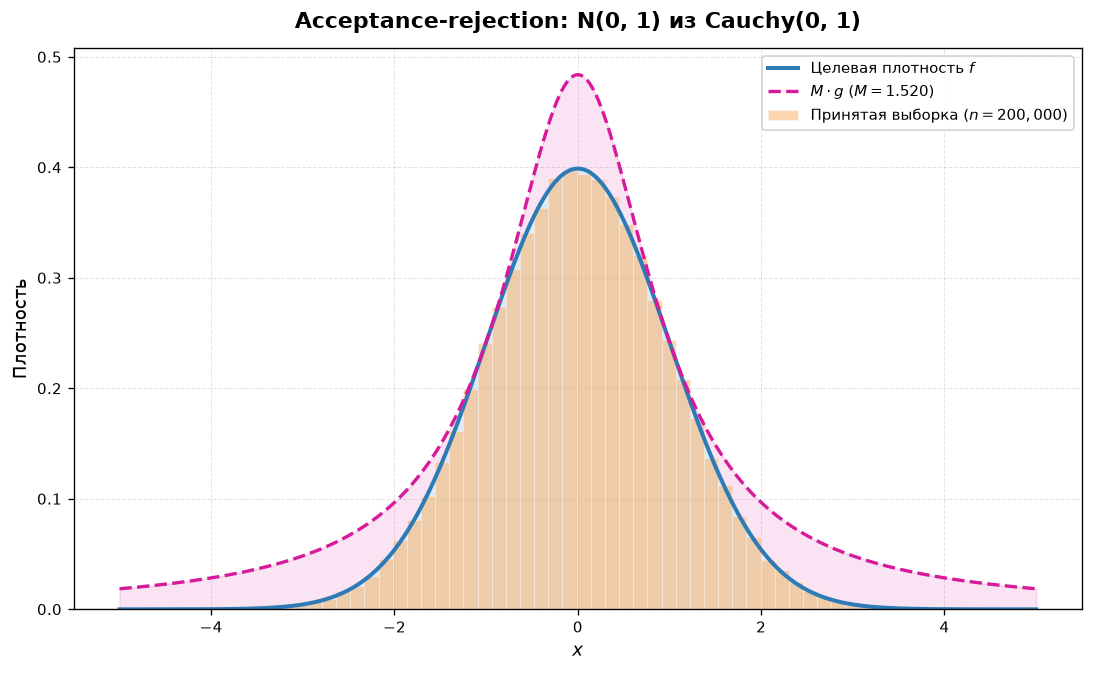

In [22]:
# Acceptance-rejection: N(0, 1) из Cauchy(0, 1)
M_normal = float(np.sqrt(2.0 * np.pi / np.e))
samples_normal_ar = acceptance_rejection(
    norm.pdf,
    cauchy.pdf,
    lambda size, random_state: cauchy.rvs(
        size=size,
        random_state=random_state,
    ),
    M_normal,
    200_000,
    RNG,
)

print(f"M = {M_normal:.4f},  доля принятия 1/M = {1.0 / M_normal:.4f}")
print(f"Выборочное среднее = {samples_normal_ar.mean():.4f}  (теор. 0)")

grid_norm = np.linspace(-5.0, 5.0, 500)
fig_ar_norm, ax_ar_norm = plt.subplots(figsize=(9, 5.5))
plot_acceptance_rejection(
    norm.pdf,
    cauchy.pdf,
    M_normal,
    grid_norm,
    samples=samples_normal_ar,
    ax=ax_ar_norm,
    title="Acceptance-rejection: N(0, 1) из Cauchy(0, 1)",
)
plt.show()

## Создание собственного непрерывного распределения: `scipy.stats.rv_continuous`

`scipy.stats.rv_continuous` — базовый класс для построения **пользовательских
непрерывных случайных величин**, полностью интегрированных в экосистему
scipy. Он предоставляет унифицированный интерфейс, аналогичный встроенным
распределениям (`norm`, `expon`, `gamma` и др.).

### Публичные методы (векторизованы)

| Метод | Назначение |
|-------|------------|
| `.pdf(x)` | Плотность $f_X(x)$ |
| `.cdf(x)` | Функция распределения $F_X(x)$ |
| `.ppf(q)` | Квантильная функция $F^{-1}(q)$ |
| `.rvs(size=n)` | Генерация выборки размера $n$ |
| `.stats(moments='mvsk')` | Моменты: среднее, дисперсия, асимметрия, эксцесс |
| `.expect(func)` | $\mathbb{E}[g(X)] = \int g(x) f(x)\,dx$ |
| `.mean()` / `.var()` / `.std()` | Среднее / дисперсия / стд. отклонение |
| `.median()` / `.interval(α)` | Медиана / интервал |
| `.support()` | Границы носителя $(a, b)$ |

### Приватные методы для переопределения

Достаточно переопределить **один** метод — остальные будут выведены
автоматически:

| Приватный метод | Когда переопределять |
|-----------------|---------------------|
| `_pdf(x)` | **Рекомендуется всегда** — базовая характеристика |
| `_cdf(x)` | Если есть замкнутая формула — ускоряет `.ppf()` |
| `_ppf(q)` | Если есть аналитическая $F^{-1}$ — ускоряет `.rvs()` |
| `_rvs(size, random_state)` | Собственная быстрая реализация генератора |

In [23]:
class GammaContinuous(rv_continuous):
    """Реализация гамма-распределения со scipy-совместимым интерфейсом.

    Parameters
    ----------
    alpha : float
        Параметр формы (α > 0).
    theta : float
        Параметр масштаба (θ > 0).
    """

    def _pdf(self, x, alpha, theta):
        return pdf_gamma(x, alpha, theta)

    def _cdf(self, x, alpha, theta):
        return cdf_gamma(x, alpha, theta)

    def _ppf(self, q, alpha, theta):
        # Аналитическая квантиль через обратную регуляризованную неполную
        # гамма-функцию: F^{-1}(q) = gammaincinv(α, q) * θ
        return gammaincinv(alpha, q) * theta


gamma_custom = GammaContinuous(a=0.0, name="gamma_custom")

In [24]:
# 1. Базовые характеристики
ALPHA_C = 2.5
THETA_C = 1.5

mean_c, var_c = gamma_custom.stats(ALPHA_C, THETA_C, moments="mv")
print("  1. Характеристики:")
print(f"     E[X] = {mean_c:.4f}   (теор. αθ = {ALPHA_C * THETA_C:.4f})")
print(f"     D[X] = {var_c:.4f}    (теор. αθ^2 = {ALPHA_C * THETA_C**2:.4f})")
print(f"     Носитель: x in [{gamma_custom.a}, {gamma_custom.b}]")

  1. Характеристики:
     E[X] = 3.7500   (теор. αθ = 3.7500)
     D[X] = 5.6250    (теор. αθ^2 = 5.6250)
     Носитель: x in [0.0, inf]


In [25]:
# 2. Точечные значения PDF и CDF
test_x = [0.5, 1.0, 2.0, 3.0, 5.0]
print("  2. Точечные значения:")
print(f"     {'x':>6s}  {'PDF':>10s}  {'CDF':>10s}")
print(f"     {'─' * 6}  {'─' * 10}  {'─' * 10}")
for x in test_x:
    print(
        f"     {x:6.2f}  "
        f"{gamma_custom.pdf(x, ALPHA_C, THETA_C):10.6f}  "
        f"{gamma_custom.cdf(x, ALPHA_C, THETA_C):10.6f}"
    )

  2. Точечные значения:
          x         PDF         CDF
     ──────  ──────────  ──────────
       0.50    0.069155    0.015252
       1.00    0.140154    0.068535
       2.00    0.203527    0.248788
       3.00    0.191968    0.450584
       5.00    0.108879    0.753366


In [26]:
# 3. Генерация и сравнение со scipy
n_large = 5_000
sample_custom = gamma_custom.rvs(ALPHA_C, THETA_C, size=n_large, random_state=42)
sample_scipy = gamma.rvs(ALPHA_C, scale=THETA_C, size=n_large, random_state=42)
print("  3. Генерация выборки (n = 5 000):")
print(
    f"     Собственноручный: среднее = {sample_custom.mean():.4f},"
    f" дисп = {sample_custom.var(ddof=1):.4f}"
)
print(
    f"     scipy.gamma:       среднее = {sample_scipy.mean():.4f},"
    f" дисп = {sample_scipy.var(ddof=1):.4f}"
)
print()

  3. Генерация выборки (n = 5 000):
     Собственноручный: среднее = 3.7237, дисп = 5.5449
     scipy.gamma:       среднее = 3.7778, дисп = 5.5785



In [27]:
# 4. Интервальные вероятности
print("  4. Вероятности интервалов:")
for a, b in [(0, 1), (1, 3), (3, np.inf)]:
    p = gamma_custom.cdf(b, ALPHA_C, THETA_C) - gamma_custom.cdf(a, ALPHA_C, THETA_C)
    print(f"     P({a:g} < X <= {b:g}) = {p:.4f}")

  4. Вероятности интервалов:
     P(0 < X <= 1) = 0.0685
     P(1 < X <= 3) = 0.3820
     P(3 < X <= inf) = 0.5494


In [28]:
# 5. Квантили
print("  5. Квантили:")
for q in [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]:
    xq = gamma_custom.ppf(q, ALPHA_C, THETA_C)
    print(f"     q = {q:.2f}  ->  x_q = {xq:.4f}")

  5. Квантили:
     q = 0.10  ->  x_q = 1.2077
     q = 0.25  ->  x_q = 2.0060
     q = 0.50  ->  x_q = 3.2636
     q = 0.75  ->  x_q = 4.9693
     q = 0.90  ->  x_q = 6.9273
     q = 0.99  ->  x_q = 11.3147


In [29]:
# 6. Моменты высших порядков и математическое ожидание функции
m, v, s, k = gamma_custom.stats(ALPHA_C, THETA_C, moments="mvsk")
print("  6. Моменты (mvsk):")
print(f"     Среднее:     {m:.4f}")
print(f"     Дисперсия:   {v:.4f}")
print(
    f"     Асимметрия:  {s:.4f}  (теор. 2/sqrt(alpha) = {2.0 / np.sqrt(ALPHA_C):.4f})"
)
print(f"     Эксцесс:     {k:.4f}  (теор. 6/α = {6.0 / ALPHA_C:.4f})")

E_x2 = gamma_custom.expect(lambda x: x**2, args=(ALPHA_C, THETA_C))
print(
    f"     E[X^2] через .expect() = {E_x2:.4f}"
    f"  (теор. α(α+1)θ^2 = {ALPHA_C * (ALPHA_C + 1.0) * THETA_C**2:.4f})"
)

  6. Моменты (mvsk):
     Среднее:     3.7500
     Дисперсия:   5.6250
     Асимметрия:  1.2649  (теор. 2/sqrt(alpha) = 1.2649)
     Эксцесс:     2.4000  (теор. 6/α = 2.4000)
     E[X^2] через .expect() = 19.6875  (теор. α(α+1)θ^2 = 19.6875)


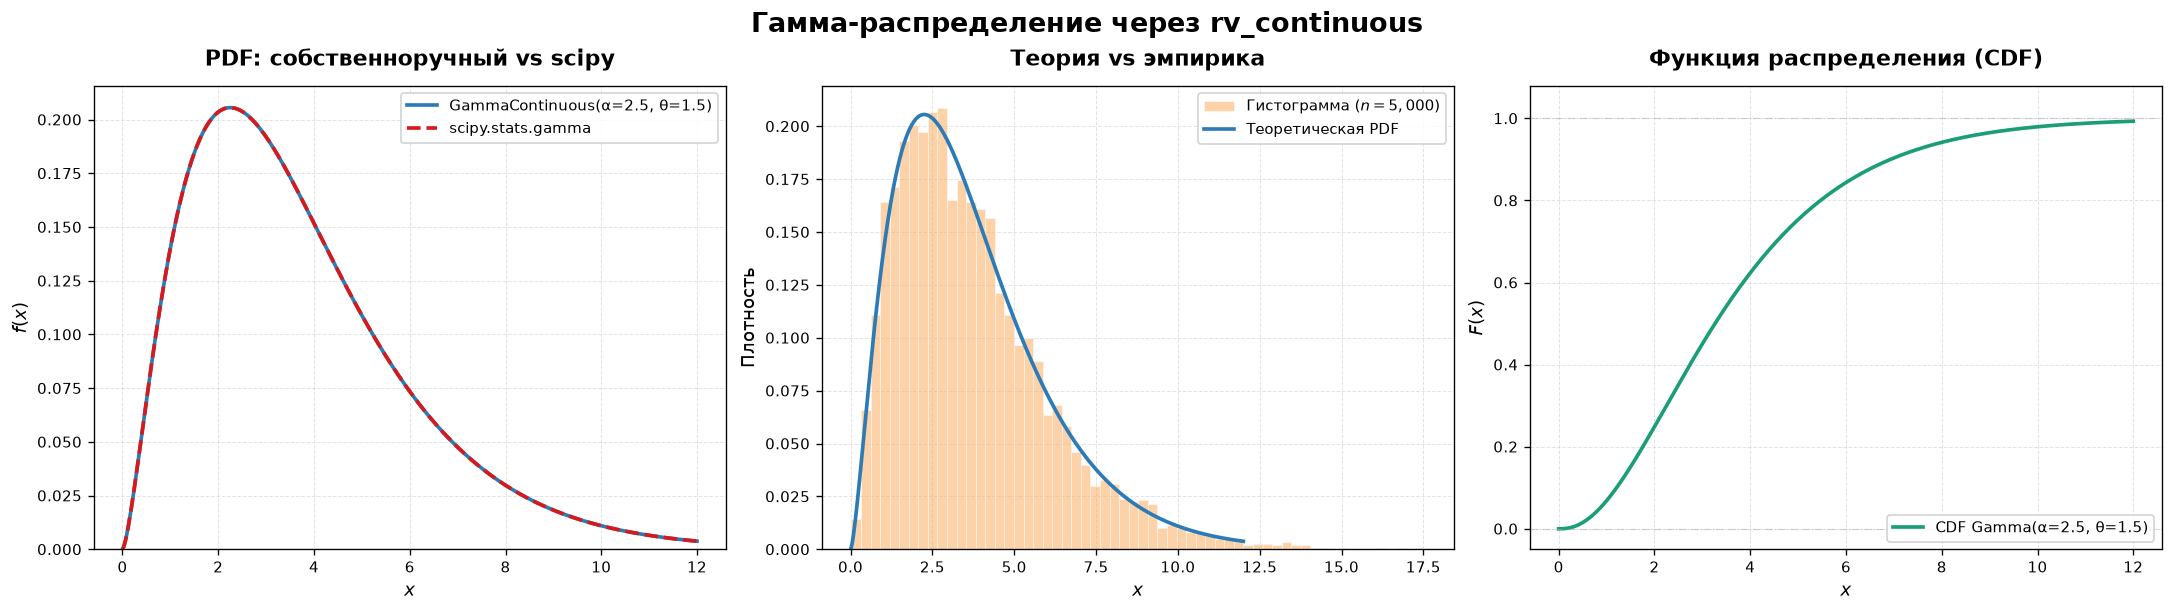

In [30]:
# Визуализация — GammaContinuous
x_disp = np.linspace(0, 12, 400)
pdf_c = gamma_custom.pdf(x_disp, ALPHA_C, THETA_C)
pdf_s = gamma.pdf(x_disp, ALPHA_C, scale=THETA_C)
cdf_c = gamma_custom.cdf(x_disp, ALPHA_C, THETA_C)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.0))

plot_two_pdfs(
    x_disp,
    pdf_c,
    x_disp,
    pdf_s,
    title="PDF: собственноручный vs scipy",
    label1=f"GammaContinuous(α={ALPHA_C}, θ={THETA_C})",
    label2="scipy.stats.gamma",
    ax=axes[0],
)

plot_histogram_vs_pdf(
    sample_custom,
    lambda x: gamma_custom.pdf(x, ALPHA_C, THETA_C),
    x_disp,
    title="Теория vs эмпирика",
    ax=axes[1],
    label_pdf="Теоретическая PDF",
)

plot_cdf_continuous(
    x_disp, cdf_c, ax=axes[2], label=f"CDF Gamma(α={ALPHA_C}, θ={THETA_C})"
)

fig.suptitle("Гамма-распределение через rv_continuous", fontsize=16, fontweight="bold")
plt.show()

## Функции от одной случайной величины

Пусть $X$ имеет плотность $f_X$, а $Y = g(X)$. Нас интересуют два вопроса:

1. **Математическое ожидание** функции:
   $$\mathbb{E}[g(X)] = \int g(x)\,f_X(x)\,dx.$$
2. **Плотность** случайной величины $Y = g(X)$ — через формулу замены
   переменной (для монотонных $g$) или через функцию распределения.

**4.1.** Пусть $X \sim \operatorname{Exp}(\lambda = 2)$ и $g(x) = x^2$.
Вычислим $\mathbb{E}[g(X)]$ и $\mathbb{P}(g(X) > 1)$ тремя способами:
численным интегрированием, через `.expect()` и методом Монте-Карло.

In [31]:
# 4.1. E[g(X)] и P(g(X) > t)
LAMBDA_L = 2.0
dist_exp_l = expon(scale=1.0 / LAMBDA_L)
pdf_x_l = partial(pdf_exp, lam=LAMBDA_L)
g_l = lambda x: x**2

E_g_quad = float(integrate.quad(lambda x: float(g_l(x) * pdf_x_l(x)), 0.0, np.inf)[0])
E_g_expect = float(dist_exp_l.expect(g_l))

samples_l = dist_exp_l.rvs(size=1_000_000, random_state=RNG)
E_g_mc = float(g_l(samples_l).mean())

print("E[X^2] для X ~ Exp(2):")
print(f"  численное интегрирование:  {E_g_quad:.6f}")
print(f"  .expect():                 {E_g_expect:.6f}")
print(f"  Монте-Карло:               {E_g_mc:.6f}")
print(f"  теоретическое 2/λ^2:       {2.0 / LAMBDA_L**2:.6f}")
print()

t_l = 1.0
P_gt_analytic = np.exp(-LAMBDA_L * np.sqrt(t_l))
P_gt_quad = float(integrate.quad(lambda x: float(pdf_x_l(x)), np.sqrt(t_l), np.inf)[0])
P_gt_mc = float((samples_l**2 > t_l).mean())

print(f"P(X^2 > {t_l:g}):")
print(f"  аналитически :             {P_gt_analytic:.6f}")
print(f"  числ. интеграл:            {P_gt_quad:.6f}")
print(f"  Монте-Карло:               {P_gt_mc:.6f}")

E[X^2] для X ~ Exp(2):
  численное интегрирование:  0.500000
  .expect():                 0.500000
  Монте-Карло:               0.498763
  теоретическое 2/λ^2:       0.500000

P(X^2 > 1):
  аналитически :             0.135335
  числ. интеграл:            0.135335
  Монте-Карло:               0.134896


**4.2.** Монотонное преобразование.

Если $g$ строго монотонна и $h = g^{-1}$ — её обратная функция, то

$$f_Y(y) = f_X\!\left(h(y)\right)\cdot\left|h'(y)\right|.$$

Задача: $X \sim U(0,1)$, $Y = -\ln(1-X)$. Тогда $h(y) = 1 - e^{-y}$,
$h'(y) = e^{-y}$ и $f_Y(y) = e^{-y}$, то есть $Y \sim \operatorname{Exp}(1)$.

In [32]:
def density_of_monotone_transform(
    pdf_x: Callable[[np.ndarray], np.ndarray],
    h: Callable[[np.ndarray], np.ndarray],
    y_grid: np.ndarray,
) -> np.ndarray:
    """Плотность Y = g(X) через обратное преобразование h = g^{-1}

    Производная h'(y) вычисляется численно методом конечных разностей
    """
    y = np.asarray(y_grid, dtype=float)

    if np.any(np.diff(y) <= 0):
        raise ValueError("y_grid должен быть строго возрастающим")

    x = np.asarray(h(y), dtype=float)

    if x.shape != y.shape:
        raise ValueError("Функция h(y) должна возвращать массив той же формы, что y")

    if not np.all(np.isfinite(x)):
        raise ValueError("Функция h(y) вернула не конечные значения")

    dh_dy = np.gradient(x, y, edge_order=2)

    f_x = np.asarray(pdf_x(x), dtype=float)

    if f_x.shape != y.shape:
        raise ValueError("pdf_x(h(y)) должна возвращать массив той же формы, что y")

    return f_x * np.abs(dh_dy)

max |f_Y - Exp(1).pdf| = 4.78e-05


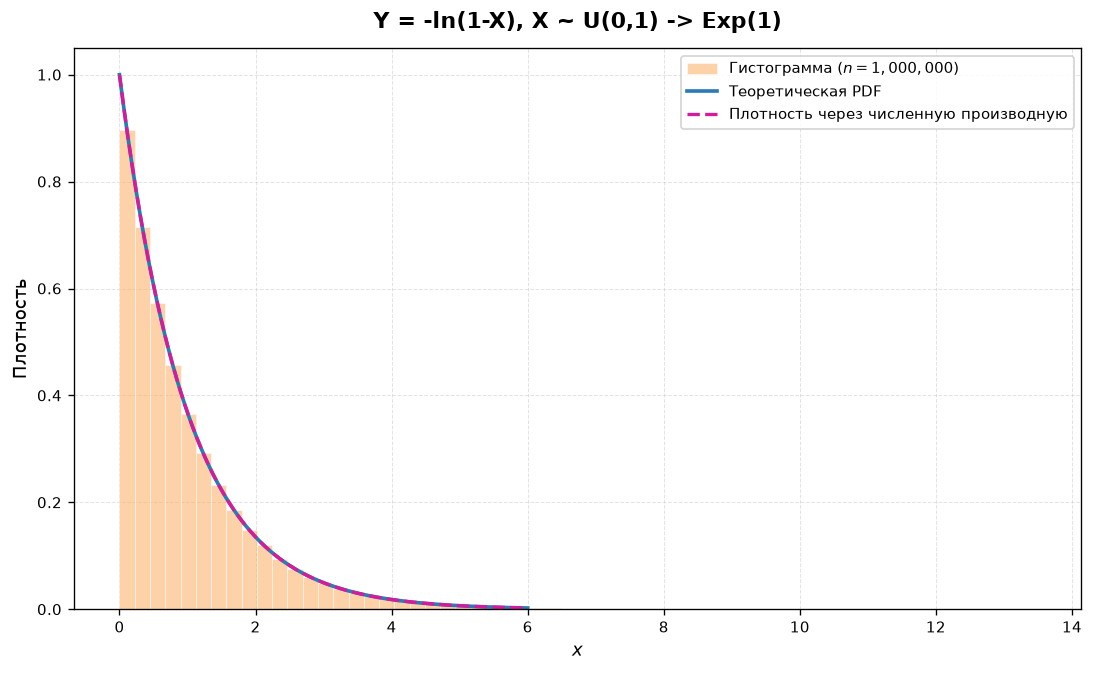

In [33]:
# Y = -ln(1 - X), X ~ U(0, 1) -> Exp(1)

h_exp = lambda y: 1.0 - np.exp(-y)
pdf_u01 = partial(pdf_uniform, a=0.0, b=1.0)

y_grid_trans = np.linspace(0.0, 6.0, 500)

f_y_mono = density_of_monotone_transform(pdf_u01, h_exp, y_grid_trans)

samples_u01 = RNG.uniform(size=1_000_000)
samples_y_mono = -np.log1p(-samples_u01)

err_mono = float(np.max(np.abs(f_y_mono - pdf_exp(y_grid_trans, 1.0))))
print(f"max |f_Y - Exp(1).pdf| = {err_mono:.2e}")

fig, ax = plt.subplots(figsize=(9, 5.5))

plot_histogram_vs_pdf(
    samples_y_mono,
    partial(pdf_exp, lam=1.0),
    y_grid_trans,
    ax=ax,
    title="Y = -ln(1-X), X ~ U(0,1) -> Exp(1)",
)

ax.plot(
    y_grid_trans,
    f_y_mono,
    color=COLORS["reference"],
    linestyle="--",
    linewidth=2.0,
    label="Плотность через численную производную",
)

ax.legend(loc="best")
plt.show()

**4.3.** Метод Монте-Карло: сходимость и оценка интегралов. Вместо аналитического интегрирования моделируем эксперимент $N$ раз и оцениваем искомые величины по выборке: $\mathbb{E}[g(X)]\approx \frac1N\sum_i g(X_i)$, а произвольный интеграл $\int_{A} f(x)dx$ — средним значением $\frac{f(X_i)\cdot \mathbb{I}_{A}(X_i)}{p(X_i)}$ по выборке $X_i$ из распределения с плотностью $p(x)$, область определения которой покрывает $A$.


In [34]:
# Оценка моментов и вероятностей для X ~ Exp(1)
LAMBDA_MC = 1.0
N_MC = 1_000_000

dist_mc = expon(scale=1.0 / LAMBDA_MC)
samples_mc = dist_mc.rvs(size=N_MC, random_state=RNG)

mean_mc = float(samples_mc.mean())
var_mc = float(samples_mc.var(ddof=1))
E_sqrt_mc = float(np.sqrt(samples_mc).mean())
P_gt2_mc = float((samples_mc > 2.0).mean())
E_sqrt_true = 0.5 * np.sqrt(np.pi)  # Gamma(3/2) = sqrt(pi)/2

w = 32
print(f"━━━ Монте-Карло оценки (N = {N_MC:,}) ━━━")
print(f"  {'E[X]':<{w}} {mean_mc:.4f}  (теор. 1)")
print(f"  {'D[X]':<{w}} {var_mc:.4f}  (теор. 1)")
print(f"  {'E[sqrt(X)]':<{w}} {E_sqrt_mc:.4f}  (теор. Gamma(3/2) = {E_sqrt_true:.4f})")
print(f"  {'P(X > 2)':<{w}} {P_gt2_mc:.4f}  (теор. e^(-2) = {np.exp(-2.0):.4f})")

━━━ Монте-Карло оценки (N = 1,000,000) ━━━
  E[X]                             1.0007  (теор. 1)
  D[X]                             1.0018  (теор. 1)
  E[sqrt(X)]                       0.8865  (теор. Gamma(3/2) = 0.8862)
  P(X > 2)                         0.1354  (теор. e^(-2) = 0.1353)


In [35]:
# Монте-Карло оценка интеграла: int_0^1 e^{-x^2} dx
u_mc = RNG.uniform(size=N_MC)
I_mc = float(np.exp(-(u_mc**2)).mean())
I_true = float(integrate.quad(lambda x: np.exp(-(x**2)), 0.0, 1.0)[0])
print(f"int_0^1 e^(-x^2) dx: Монте-Карло = {I_mc:.6f},  точное (quad) = {I_true:.6f}")

int_0^1 e^(-x^2) dx: Монте-Карло = 0.746870,  точное (quad) = 0.746824


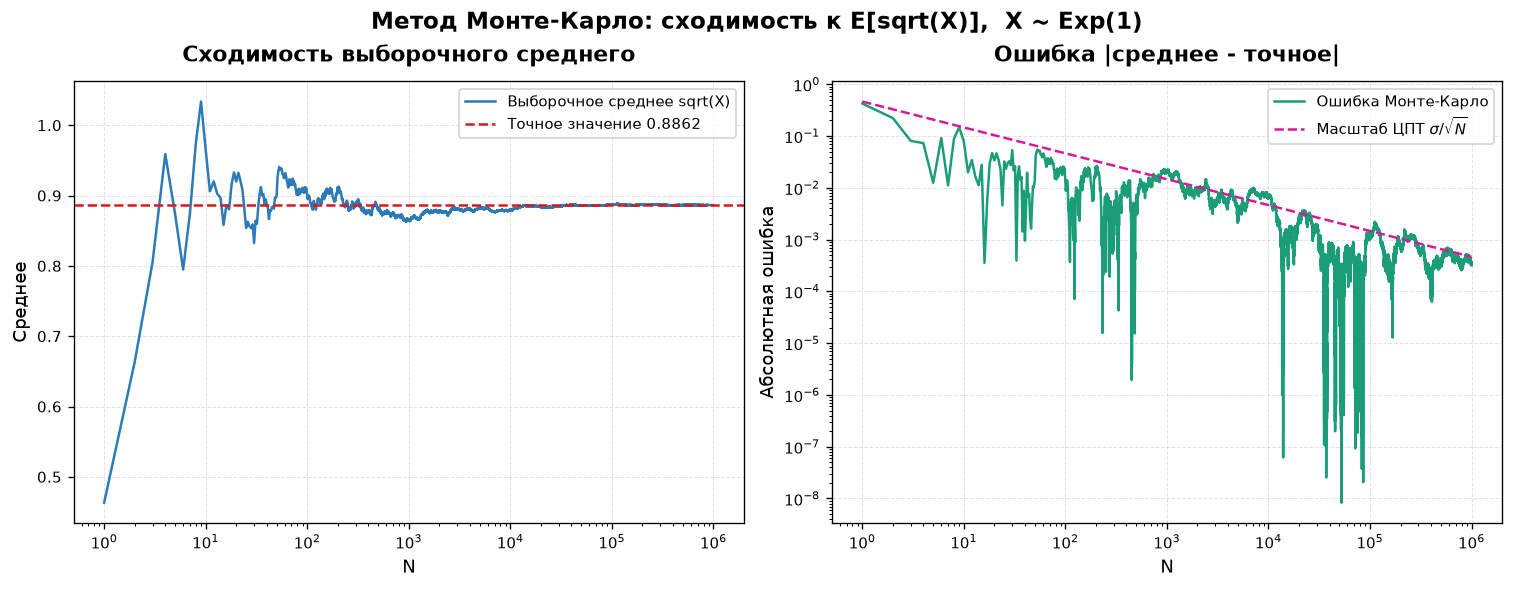

In [37]:
# Сходимость выборочного среднего E[sqrt(X)] с ростом N
running_sqrt = np.cumsum(np.sqrt(samples_mc)) / np.arange(1, N_MC + 1)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

axes[0].plot(
    np.arange(1, N_MC + 1),
    running_sqrt,
    linewidth=1.5,
    color=COLORS["theory"],
    label="Выборочное среднее sqrt(X)",
)
axes[0].axhline(
    E_sqrt_true,
    color=COLORS["inverse"],
    linestyle="--",
    linewidth=1.5,
    label=f"Точное значение {E_sqrt_true:.4f}",
)
axes[0].set_xscale("log")
axes[0].set_title("Сходимость выборочного среднего", fontweight="bold", pad=12)
axes[0].set_xlabel("N")
axes[0].set_ylabel("Среднее")
axes[0].legend(loc="best")

axes[1].loglog(
    np.arange(1, N_MC + 1),
    np.abs(running_sqrt - E_sqrt_true),
    linewidth=1.5,
    color=COLORS["cdf"],
    label="Ошибка Монте-Карло",
)
n_arr = np.arange(1, N_MC + 1)
axes[1].loglog(
    n_arr,
    np.std(np.sqrt(samples_mc)) / np.sqrt(n_arr),
    linestyle="--",
    color=COLORS["reference"],
    label=r"Масштаб ЦПТ $\sigma / \sqrt{N}$",
)
axes[1].set_title("Ошибка |среднее - точное|", fontweight="bold", pad=12)
axes[1].set_xlabel("N")
axes[1].set_ylabel("Абсолютная ошибка")
axes[1].legend(loc="best")

fig.suptitle(
    "Метод Монте-Карло: сходимость к E[sqrt(X)],  X ~ Exp(1)",
    fontsize=14,
    fontweight="bold",
)
plt.show()

## Совместное распределение двух величин

Пара $(X, Y)$ задаётся **совместной плотностью** $f_{X,Y}(x, y) \ge 0$ с
нормировкой $\iint f = 1$. По ней восстанавливаются:

- **маргинальные плотности**:
  $f_X(x) = \int f(x, y)\,dy$,
  $f_Y(y) = \int f(x, y)\,dx$;
- **вероятность на множестве** $A$:
  $\displaystyle\mathbb{P}\!\left((X, Y) \in A\right)
  = \iint_A f(x, y)\,dx\,dy$;
- **независимость**: $X$ и $Y$ независимы тогда и только тогда, когда
  $f(x, y) = f_X(x)\,f_Y(y)$ почти всюду.

**5.1.** Совместная плотность $f(x, y) = c\,(x + y)$ на квадрате $[0,1]^2$.
Найдём нормировочную константу, маргинальные плотности, проверим
независимость и вычислим вероятности на множествах.

In [38]:
# Нормировка: двойной интеграл (x + y) dx dy = 1  ->  c = 1
norm_const = integrate.dblquad(
    lambda y, x: x + y, 0.0, 1.0, lambda x: 0.0, lambda x: 1.0
)[0]
c_joint = 1.0 / norm_const
print(f"Нормировочная константа c = {c_joint:.6f}")


def joint_pdf_xy(x, y):
    """f(x, y) = c (x + y) на [0,1]^2"""
    return c_joint * (x + y)


def marginal_x(x):
    x = np.asarray(x, dtype=float)
    return np.where((x >= 0) & (x <= 1), x + 0.5, 0.0)


def marginal_y(y):
    y = np.asarray(y, dtype=float)
    return np.where((y >= 0) & (y <= 1), y + 0.5, 0.0)


# Проверка маргинального распределения численным интегрированием
x_probe = np.array([0.1, 0.3, 0.5, 0.8])
marg_x_num = np.array(
    [integrate.quad(lambda y: joint_pdf_xy(x, y), 0.0, 1.0)[0] for x in x_probe]
)
print(
    "f_X(x) численно:",
    np.round(marg_x_num, 4),
    "  аналитически:",
    np.round(marginal_x(x_probe), 4),
)
print("Независимость: f(x,y) = x+y, а f_X*f_Y = (x+1/2)(y+1/2) -> зависимы")

Нормировочная константа c = 1.000000
f_X(x) численно: [0.6 0.8 1.  1.3]   аналитически: [0.6 0.8 1.  1.3]
Независимость: f(x,y) = x+y, а f_X*f_Y = (x+1/2)(y+1/2) -> зависимы


In [39]:
# Вероятности на множествах
p_sum_le1 = integrate.dblquad(
    lambda y, x: c_joint * (x + y), 0.0, 1.0, lambda x: 0.0, lambda x: 1.0 - x
)[0]
p_x_lt_y = integrate.dblquad(
    lambda y, x: c_joint * (x + y), 0.0, 1.0, lambda x: x, lambda x: 1.0
)[0]
p_disk = integrate.dblquad(
    lambda y, x: c_joint * (x + y),
    0.0,
    1.0,
    lambda x: 0.0,
    lambda x: np.sqrt(1.0 - x**2),
)[0]

print(f"P(X + Y <= 1)     = {p_sum_le1:.6f}   (теор. 1/3 = {1.0 / 3.0:.6f})")
print(f"P(X < Y)          = {p_x_lt_y:.6f}   (теор. 1/2 = {1.0 / 2.0:.6f})")
print(f"P(X^2 + Y^2 <= 1) = {p_disk:.6f}   (теор. 2/3 = {2.0 / 3.0:.6f})")

P(X + Y <= 1)     = 0.333333   (теор. 1/3 = 0.333333)
P(X < Y)          = 0.500000   (теор. 1/2 = 0.500000)
P(X^2 + Y^2 <= 1) = 0.666667   (теор. 2/3 = 0.666667)


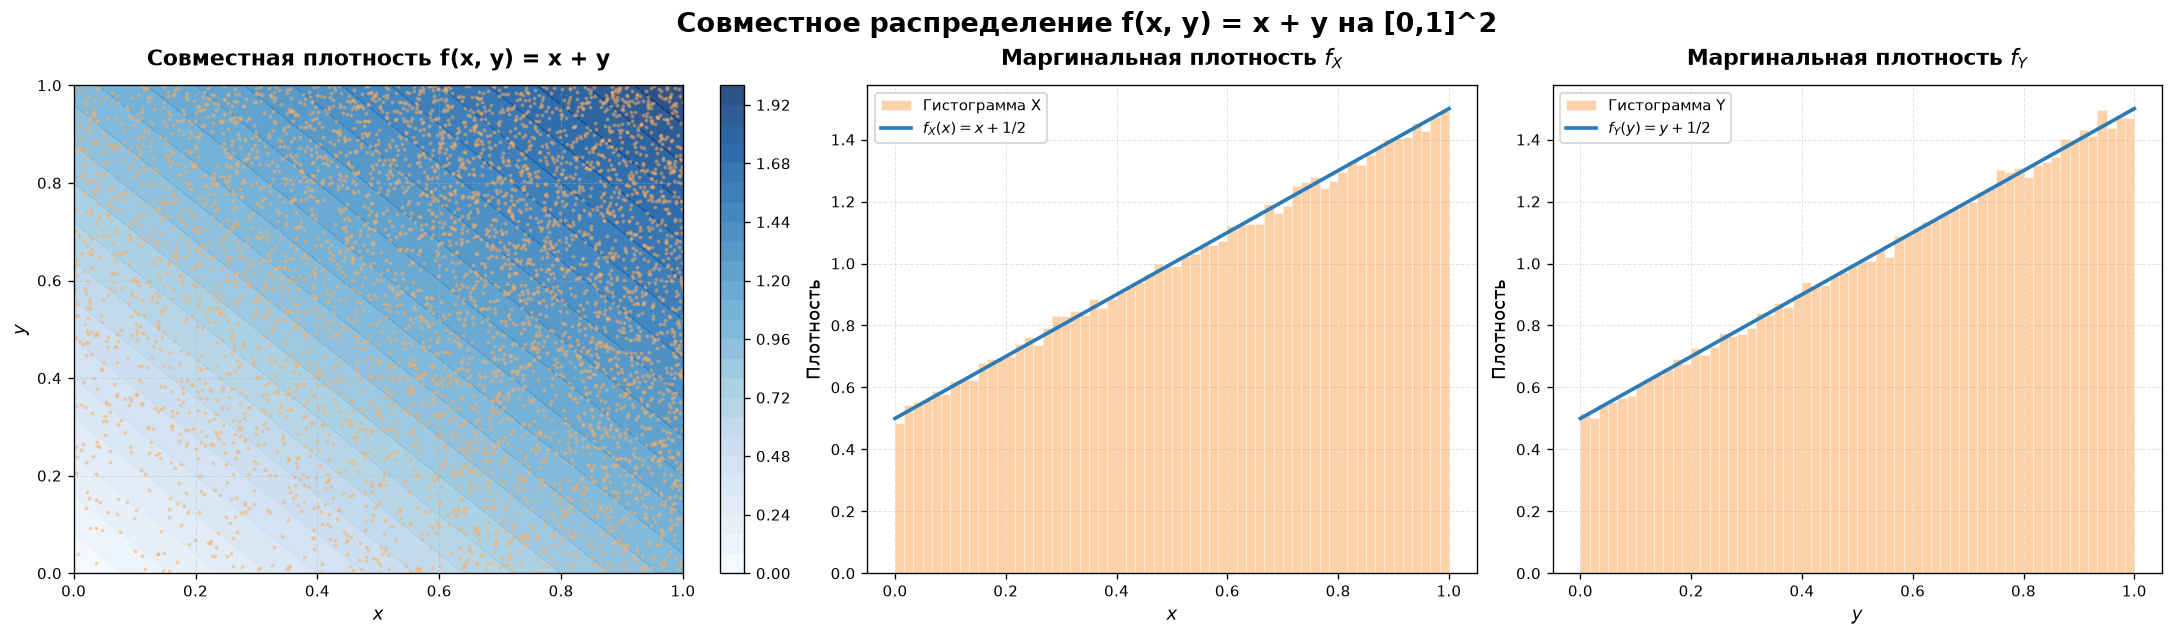

In [40]:
def sample_joint_ar(n: int, rng: np.random.Generator = RNG):
    """Выборка из f(x,y) = x+y на [0,1]^2  (M = 2)"""
    xs, ys = [], []
    total = 0
    while total < n:
        remaining = n - total
        n_try = int(np.ceil(remaining * 2.0 * 1.25))
        x = rng.uniform(size=n_try)
        y = rng.uniform(size=n_try)
        u = rng.uniform(size=n_try)
        accept = u <= (x + y) / 2.0
        if accept.any():
            xs.append(x[accept])
            ys.append(y[accept])
            total += int(accept.sum())
    return np.concatenate(xs)[:n], np.concatenate(ys)[:n]


sx, sy = sample_joint_ar(200_000)

x_grid_j = np.linspace(0.0, 1.0, 200)
y_grid_j = np.linspace(0.0, 1.0, 200)
Xg, Yg = np.meshgrid(x_grid_j, y_grid_j)
Zg = joint_pdf_xy(Xg, Yg)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

cs = axes[0].contourf(Xg, Yg, Zg, levels=30, cmap="Blues", alpha=0.85)
axes[0].scatter(sx[::40], sy[::40], s=2, color=COLORS["empirical"], alpha=0.4)
axes[0].set_title("Совместная плотность f(x, y) = x + y", fontweight="bold", pad=12)
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
fig.colorbar(cs, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].hist(
    sx,
    bins=60,
    density=True,
    range=(0, 1),
    color=COLORS["empirical"],
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label="Гистограмма X",
)
axes[1].plot(
    x_grid_j,
    marginal_x(x_grid_j),
    color=COLORS["theory"],
    linewidth=2.2,
    label="$f_X(x) = x + 1/2$",
)
axes[1].set_title("Маргинальная плотность $f_X$", fontweight="bold", pad=12)
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Плотность")
axes[1].legend(loc="best")

axes[2].hist(
    sy,
    bins=60,
    density=True,
    range=(0, 1),
    color=COLORS["empirical"],
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label="Гистограмма Y",
)
axes[2].plot(
    y_grid_j,
    marginal_y(y_grid_j),
    color=COLORS["theory"],
    linewidth=2.2,
    label="$f_Y(y) = y + 1/2$",
)
axes[2].set_title("Маргинальная плотность $f_Y$", fontweight="bold", pad=12)
axes[2].set_xlabel("$y$")
axes[2].set_ylabel("Плотность")
axes[2].legend(loc="best")

fig.suptitle(
    "Совместное распределение f(x, y) = x + y на [0,1]^2",
    fontsize=16,
    fontweight="bold",
)
plt.show()

**5.2.** Равномерное распределение на треугольнике $D = \{0 < y < x < 1\}$.
Площадь $D$ равна $1/2$, поэтому $f(x, y) = 2$ на $D$.

$$f_X(x) = 2x,\qquad f_Y(y) = 2(1 - y)$$

In [41]:
def joint_tri(x, y):
    """f(x, y) = 2 на треугольнике 0 < y < x < 1"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return np.where((x > 0) & (x < 1) & (y > 0) & (y < x), 2.0, 0.0)


def marginal_tri_x(x):
    x = np.asarray(x, dtype=float)
    return np.where((x >= 0) & (x <= 1), 2.0 * x, 0.0)


def marginal_tri_y(y):
    y = np.asarray(y, dtype=float)
    return np.where((y >= 0) & (y <= 1), 2.0 * (1.0 - y), 0.0)


# Нормировка: площадь треугольника = 1/2  ->  c = 2
area_tri = integrate.dblquad(lambda y, x: 1.0, 0.0, 1.0, lambda x: 0.0, lambda x: x)[0]
print(f"Площадь треугольника = {area_tri:.6f}  ->  c = {1.0 / area_tri:.6f}")

# Вероятность на множестве {X + Y <= 1}
p_tri = integrate.dblquad(
    lambda y, x: 2.0, 0.0, 1.0, lambda x: 0.0, lambda x: np.minimum(x, 1.0 - x)
)[0]
print(f"P(X + Y <= 1) = {p_tri:.6f}   (теор. 1/2)")
print("Независимость: f_X(x)f_Y(y) = 4x(1-y) != 2 = f(x,y) -> зависимы")

Площадь треугольника = 0.500000  ->  c = 2.000000
P(X + Y <= 1) = 0.500000   (теор. 1/2)
Независимость: f_X(x)f_Y(y) = 4x(1-y) != 2 = f(x,y) -> зависимы


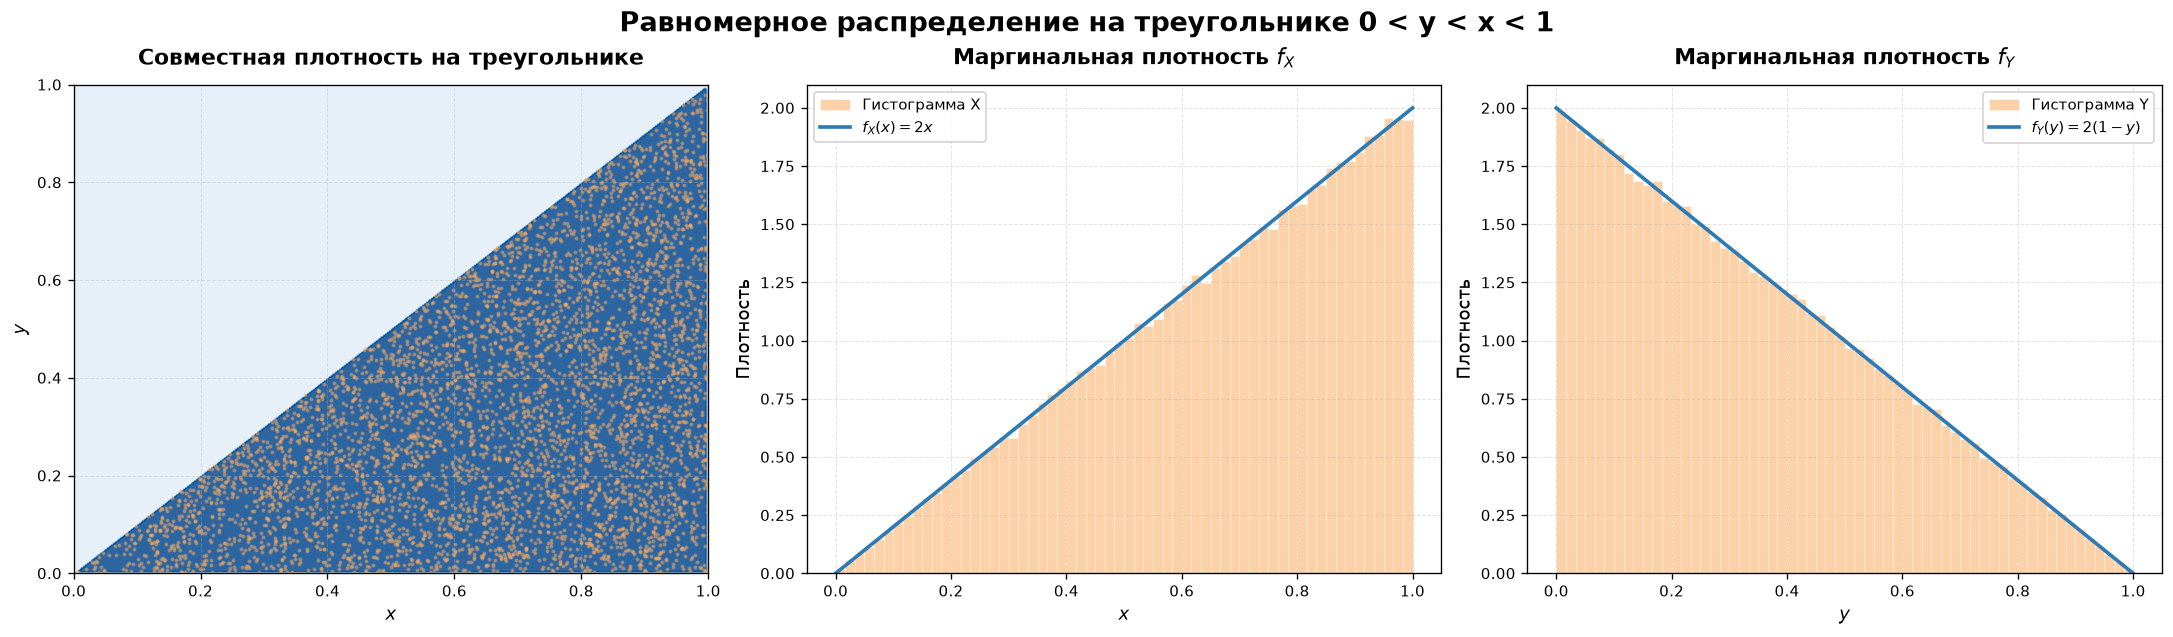

In [42]:
def sample_triangle(n: int, rng: np.random.Generator):
    """Выборка из равномерного распределения на треугольнике (y < x)"""
    u1 = rng.uniform(size=n)
    u2 = rng.uniform(size=n)

    x = np.maximum(u1, u2)
    y = np.minimum(u1, u2)

    return x, y


sx_t, sy_t = sample_triangle(200_000, RNG)

Xg_t, Yg_t = np.meshgrid(x_grid_j, y_grid_j)
Zg_t = joint_tri(Xg_t, Yg_t)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

axes[0].contourf(Xg_t, Yg_t, Zg_t, levels=5, cmap="Blues", alpha=0.85)
axes[0].scatter(sx_t[::40], sy_t[::40], s=2, color=COLORS["empirical"], alpha=0.4)
axes[0].set_title("Совместная плотность на треугольнике", fontweight="bold", pad=12)
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")

axes[1].hist(
    sx_t,
    bins=60,
    density=True,
    range=(0, 1),
    color=COLORS["empirical"],
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label="Гистограмма X",
)
axes[1].plot(
    x_grid_j,
    marginal_tri_x(x_grid_j),
    color=COLORS["theory"],
    linewidth=2.2,
    label="$f_X(x) = 2x$",
)
axes[1].set_title("Маргинальная плотность $f_X$", fontweight="bold", pad=12)
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("Плотность")
axes[1].legend(loc="best")

axes[2].hist(
    sy_t,
    bins=60,
    density=True,
    range=(0, 1),
    color=COLORS["empirical"],
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    label="Гистограмма Y",
)
axes[2].plot(
    y_grid_j,
    marginal_tri_y(y_grid_j),
    color=COLORS["theory"],
    linewidth=2.2,
    label="$f_Y(y) = 2(1-y)$",
)
axes[2].set_title("Маргинальная плотность $f_Y$", fontweight="bold", pad=12)
axes[2].set_xlabel("$y$")
axes[2].set_ylabel("Плотность")
axes[2].legend(loc="best")

fig.suptitle(
    "Равномерное распределение на треугольнике 0 < y < x < 1",
    fontsize=16,
    fontweight="bold",
)
plt.show()

## Функции двух независимых случайных величин

Пусть $X$ и $Y$ независимы и имеют плотности $f_X$ и $f_Y$. Рассмотрим
плотности суммы, произведения и частного. Каждую формулу будем проверять
численно и методом Монте-Карло (гистограммой).

**6.1.** Сумма (свёртка):

$$f_Z(z) = \int f_X(x)\,f_Y(z - x)\,dx.$$

Пример A: $X, Y \sim U(0,1)$, тогда $Z = X + Y$ — треугольное распределение
на $[0, 2]$.

In [43]:
def pdf_sum_grid(
    pdf_x: Callable[[np.ndarray], np.ndarray],
    pdf_y: Callable[[np.ndarray], np.ndarray],
    z_grid: np.ndarray,
    x_lo: float,
    x_hi: float,
    n: int = 2**14,
) -> np.ndarray:
    """Плотность суммы Z = X + Y для независимых X и Y."""

    if n < 2:
        raise ValueError("n должно быть не меньше 2.")
    if x_hi <= x_lo:
        raise ValueError("x_hi должно быть больше x_lo.")

    x = np.linspace(x_lo, x_hi, n)
    dx = x[1] - x[0]

    fx = np.asarray(pdf_x(x), dtype=float)
    fy = np.asarray(pdf_y(x), dtype=float)

    if fx.shape != x.shape or fy.shape != x.shape:
        raise ValueError("PDF-функции должны возвращать массив формы x.")

    conv = fftconvolve(fx, fy, mode="full") * dx

    k = np.arange(conv.size)
    i_left = np.maximum(0, k - (n - 1))
    i_right = np.minimum(n - 1, k)

    conv -= 0.5 * dx * (fx[i_left] * fy[k - i_left] + fx[i_right] * fy[k - i_right])

    conv = np.maximum(conv, 0.0)

    z = 2 * x_lo + k * dx

    return np.interp(z_grid, z, conv, left=0.0, right=0.0)

max |f_Z - треугольная| = 5.72e-16


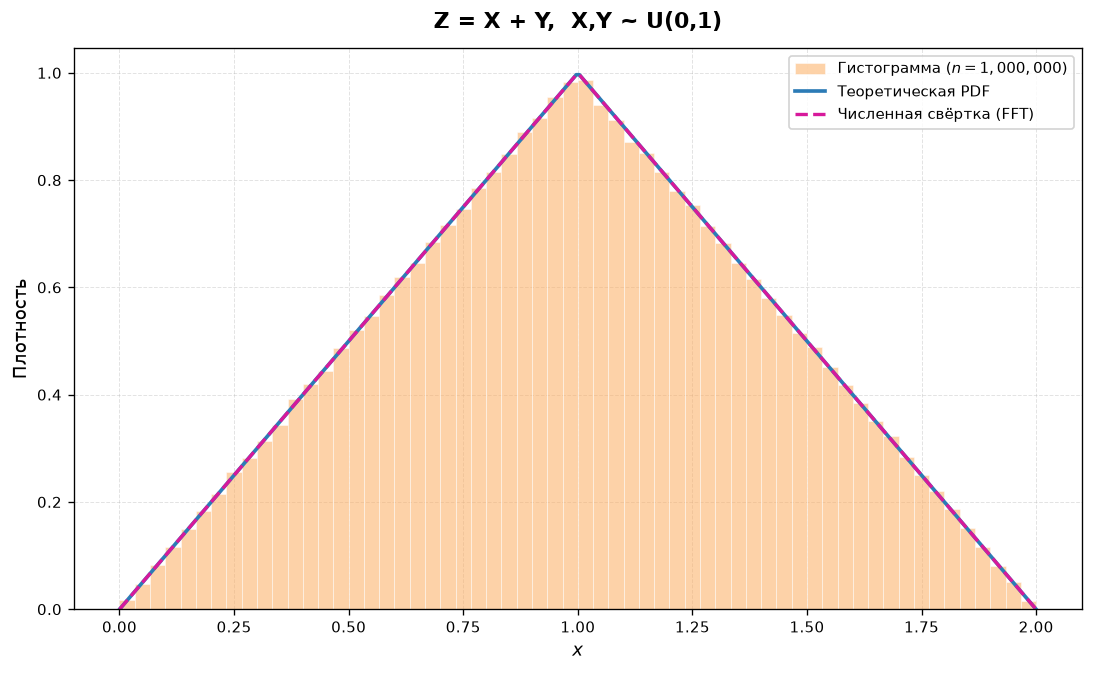

In [44]:
# Z = X + Y,  X, Y ~ U(0, 1)  ->  треугольное распределение
def pdf_triangular(z: np.ndarray) -> np.ndarray:
    z = np.asarray(z, dtype=float)
    return np.where((z >= 0) & (z <= 1), z, np.where((z > 1) & (z <= 2), 2.0 - z, 0.0))


z_grid_sum = np.linspace(0.0, 2.0, 300)
f_sum_unif = pdf_sum_grid(pdf_u01, pdf_u01, z_grid_sum, 0.0, 1.0)
err_sum = float(np.max(np.abs(f_sum_unif - pdf_triangular(z_grid_sum))))
print(f"max |f_Z - треугольная| = {err_sum:.2e}")

samples_sum_unif = RNG.uniform(size=(2, 1_000_000)).sum(axis=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_histogram_vs_pdf(
    samples_sum_unif,
    pdf_triangular,
    z_grid_sum,
    ax=ax,
    hist_range=(0.0, 2.0),
    title="Z = X + Y,  X,Y ~ U(0,1)",
)
ax.plot(
    z_grid_sum,
    f_sum_unif,
    color=COLORS["reference"],
    linestyle="--",
    linewidth=2.0,
    label="Численная свёртка (FFT)",
)
ax.legend(loc="best")
plt.show()

max |f_Z - Gamma(2,1).pdf| = 5.33e-08


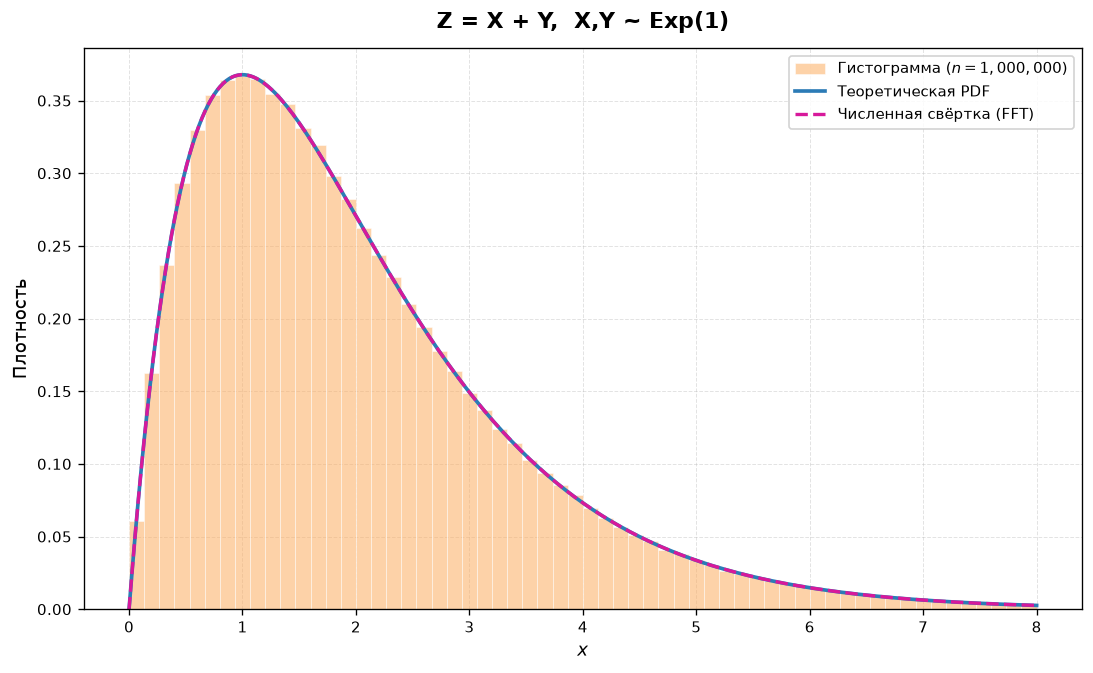

In [45]:
# Пример B: Z = X + Y,  X, Y ~ Exp(1)  ->  Gamma(2, 1)
pdf_e1 = partial(pdf_exp, lam=1.0)
z_grid_exp_sum = np.linspace(0.0, 8.0, 300)

f_sum_exp = pdf_sum_grid(pdf_e1, pdf_e1, z_grid_exp_sum, 0.0, 16.0, n=2**15)

gamma2 = gamma(a=2.0, scale=1.0)
err_sum_exp = float(np.max(np.abs(f_sum_exp - gamma2.pdf(z_grid_exp_sum))))
print(f"max |f_Z - Gamma(2,1).pdf| = {err_sum_exp:.2e}")

samples_sum_exp = RNG.exponential(scale=1.0, size=(2, 1_000_000)).sum(axis=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_histogram_vs_pdf(
    samples_sum_exp,
    gamma2.pdf,
    z_grid_exp_sum,
    ax=ax,
    hist_range=(0.0, 8.0),
    title="Z = X + Y,  X,Y ~ Exp(1)",
)
ax.plot(
    z_grid_exp_sum,
    f_sum_exp,
    color=COLORS["reference"],
    linestyle="--",
    linewidth=2.0,
    label="Численная свёртка (FFT)",
)
ax.legend(loc="best")
plt.show()

**6.2.** Произведение (свёртка Меллина):

$$f_Z(z) = \int f_X(x)\,f_Y\!\left(\frac{z}{x}\right)\frac{dx}{|x|}.$$

Пример: $X, Y \sim U(0,1)$, $Z = XY$. Тогда $f_Z(z) = -\ln z$ для
$z \in (0, 1]$.

In [46]:
def pdf_product(
    pdf_x: Callable[[np.ndarray], np.ndarray],
    pdf_y: Callable[[np.ndarray], np.ndarray],
    z_grid: np.ndarray,
    x_lo: float,
    x_hi: float,
    n: int = 4096,
) -> np.ndarray:
    """Плотность произведения Z = X * Y
    для независимых X и Y, численное интегрирование по x
    """

    if n < 2:
        raise ValueError("n должно быть не меньше 2.")
    if x_hi <= x_lo:
        raise ValueError("x_hi должно быть больше x_lo.")

    x = np.linspace(x_lo, x_hi, n)
    z = np.asarray(z_grid, dtype=float)

    if z.ndim != 1:
        raise ValueError("z_grid должен быть одномерным массивом.")

    fx = np.asarray(pdf_x(x), dtype=float)

    if fx.shape != x.shape:
        raise ValueError("pdf_x должен возвращать массив формы x.")

    if x_lo <= 0 <= x_hi and np.any(z == 0):
        raise ValueError(
            "При z = 0 и интервале x, содержащем 0, "
            "нужна отдельная обработка возможной сингулярности."
        )
    # Broadcasting вместо явного meshgrid.
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ratio = z[:, None] / x[None, :]
        fy = np.asarray(pdf_y(ratio), dtype=float)

        if fy.shape != ratio.shape:
            raise ValueError("pdf_y должна возвращать массив формы ratio.")

        integrand = fx[None, :] * fy / np.abs(x[None, :])

    zero_x = np.broadcast_to(x[None, :] == 0, integrand.shape)
    allowed = zero_x & (z[:, None] != 0)
    bad = ~np.isfinite(integrand)

    integrand[bad & allowed] = 0.0

    return np.trapezoid(integrand, x, axis=1)

max |f_Z - (-ln z)| = 1.16e-02


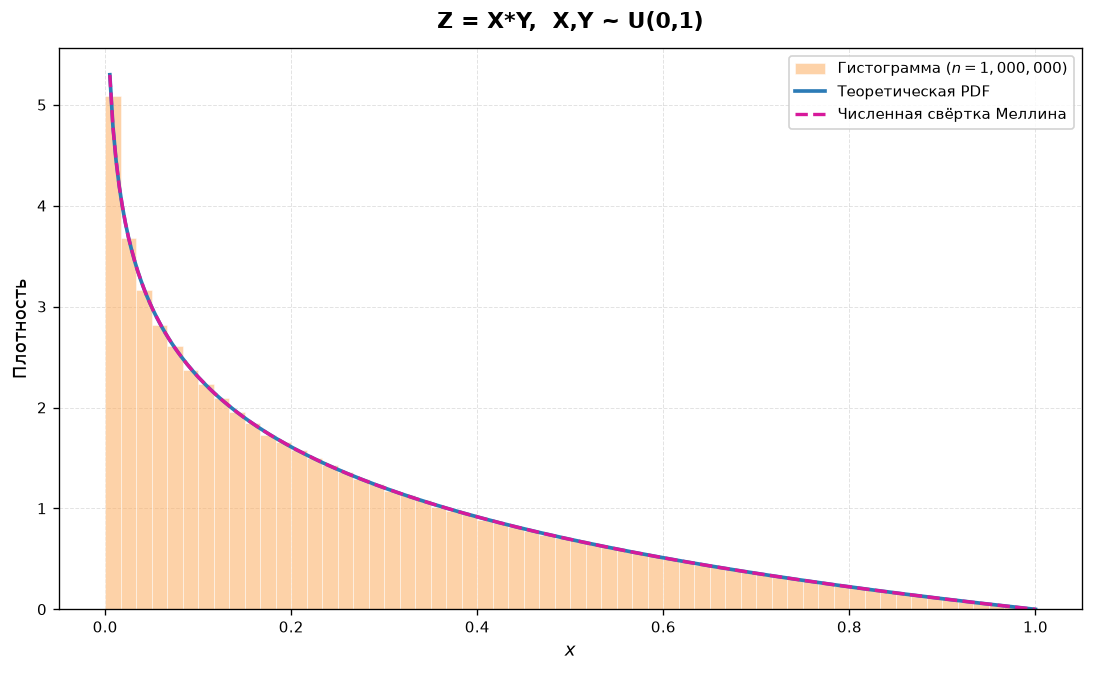

In [47]:
# Z = X*Y,  X, Y ~ U(0, 1)  ->  f_Z(z) = -ln(z)
z_grid_prod = np.linspace(0.005, 1.0, 300)
f_prod = pdf_product(pdf_u01, pdf_u01, z_grid_prod, 0.0, 1.0)
err_prod = float(np.max(np.abs(f_prod + np.log(z_grid_prod))))
print(f"max |f_Z - (-ln z)| = {err_prod:.2e}")

samples_prod = RNG.uniform(size=(2, 1_000_000)).prod(axis=0)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_histogram_vs_pdf(
    samples_prod,
    lambda z: -np.log(z),
    z_grid_prod,
    ax=ax,
    hist_range=(0.0, 1.0),
    title="Z = X*Y,  X,Y ~ U(0,1)",
)
ax.plot(
    z_grid_prod,
    f_prod,
    color=COLORS["reference"],
    linestyle="--",
    linewidth=2.0,
    label="Численная свёртка Меллина",
)
ax.legend(loc="best")
plt.show()

**6.3.** Частное:

$$f_Z(z) = \int f_X(zy)\,f_Y(y)\,|y|\,dy.$$

Пример: $X, Y \sim \mathcal{N}(0,1)$, $Z = X/Y$ — распределение Коши
$f_Z(z) = \dfrac{1}{\pi(1 + z^2)}$.

In [48]:
def pdf_ratio(
    pdf_x: Callable[[np.ndarray], np.ndarray],
    pdf_y: Callable[[np.ndarray], np.ndarray],
    z_grid: np.ndarray,
    y_lo: float,
    y_hi: float,
    n: int = 8193,
) -> np.ndarray:
    """Плотность частного Z = X / Y для независимых X и Y"""

    if n < 2:
        raise ValueError("n должно быть не меньше 2")
    if y_hi <= y_lo:
        raise ValueError("y_hi должно быть больше y_lo")

    n = n if n % 2 == 1 else n + 1
    z = np.asarray(z_grid, dtype=float)

    if z.ndim != 1:
        raise ValueError("z_grid должен быть одномерным массивом")

    if y_lo < 0 < y_hi:
        intervals = n - 1
        n_left = round(intervals * (-y_lo) / (y_hi - y_lo))
        n_left = min(max(n_left, 1), intervals - 1)
        n_right = intervals - n_left

        y = np.concatenate(
            (
                np.linspace(y_lo, 0.0, n_left + 1),
                np.linspace(0.0, y_hi, n_right + 1)[1:],
            )
        )
    else:
        y = np.linspace(y_lo, y_hi, n)

    fy = np.asarray(pdf_y(y), dtype=float)

    if fy.shape != y.shape:
        raise ValueError("pdf_y должен возвращать массив формы y")

    with np.errstate(over="ignore", invalid="ignore"):
        x_values = z[:, None] * y[None, :]
        fx_values = np.asarray(pdf_x(x_values), dtype=float)

    if fx_values.shape != x_values.shape:
        raise ValueError(
            "pdf_x должен возвращать массив той же формы, что и z[:, None] * y[None, :]"
        )

    integrand = fx_values * fy[None, :] * np.abs(y)[None, :]

    if not np.all(np.isfinite(integrand)):
        raise FloatingPointError("В интеграле обнаружены NaN или бесконечности")

    return np.trapezoid(integrand, y, axis=1)

max |f_Z - Cauchy.pdf| = 2.28e-07


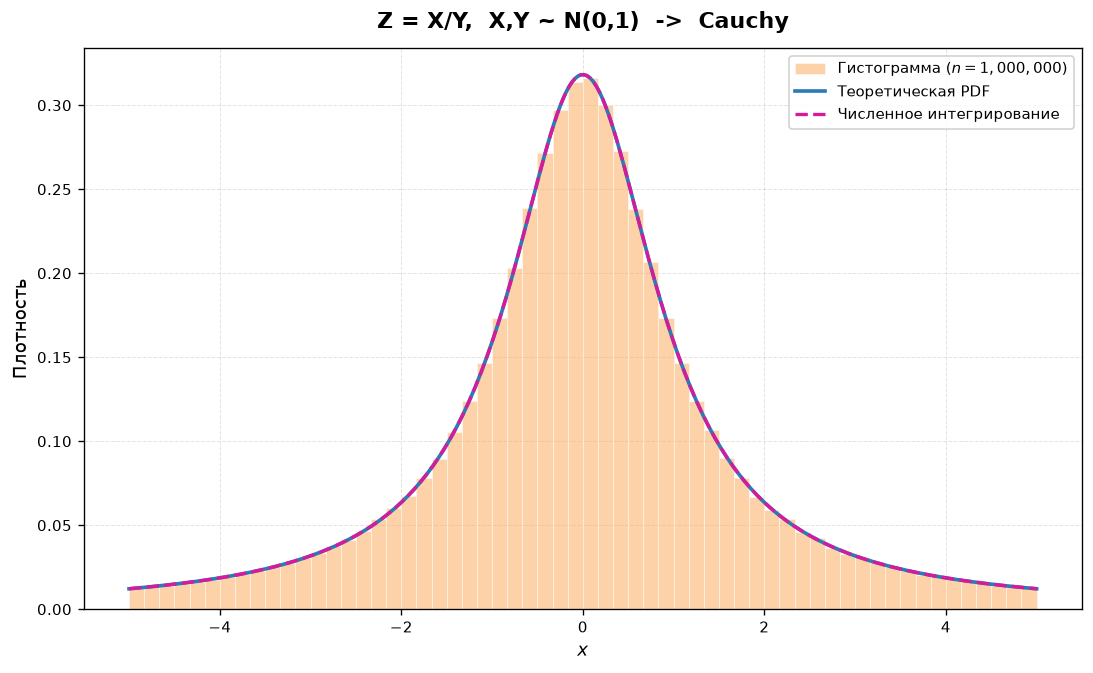

In [49]:
# Z = X/Y,  X, Y ~ N(0, 1)  ->  Cauchy(0, 1)
z_grid_ratio = np.linspace(-5.0, 5.0, 300)

f_ratio = pdf_ratio(norm.pdf, norm.pdf, z_grid_ratio, -12.0, 12.0)
err_ratio = float(np.max(np.abs(f_ratio - cauchy.pdf(z_grid_ratio))))
print(f"max |f_Z - Cauchy.pdf| = {err_ratio:.2e}")

samples_ratio = norm.rvs(size=1_000_000, random_state=RNG) / norm.rvs(
    size=1_000_000, random_state=RNG
)


n_bins = 60
bin_width = 10.0 / n_bins
hist_weights = np.full(len(samples_ratio), 1.0 / (len(samples_ratio) * bin_width))

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_histogram_vs_pdf(
    samples_ratio,
    cauchy.pdf,
    z_grid_ratio,
    ax=ax,
    hist_range=(-5.0, 5.0),
    bins=n_bins,
    weights=hist_weights,
    title="Z = X/Y,  X,Y ~ N(0,1)  ->  Cauchy",
)
ax.plot(
    z_grid_ratio,
    f_ratio,
    color=COLORS["reference"],
    linestyle="--",
    linewidth=2.0,
    label="Численное интегрирование",
)
ax.legend(loc="best")
plt.show()